<div align="center">
  <h4>ECM514 – Ciência de Dados</h4>
  <h4>Projeto Desafio do 2º Semestre</h4>
  <h1>Detecção e Diagnóstico de Anomalias em Sinais de Vibração</h1>
</div>

### Integrantes:

André Renato Almeida Abreu RA: 22.01255-9

Arthur Jin Woo Lee RA: 22.01519-0

Fernando Minharro Alves Gimenez RA: 22.00833-0

Leonardo Henrique Dias Moura RA: 21.01837-5

Leonardo Tagliati da Silva RA: 22.00170-0

# Descrição do Dataset

## Origem e Setup Físico do Experimento
Os dados utilizados são do dataset público **UOEMD-VAFCVS** (*University of Ottawa Electric Motor Dataset – Vibration and Acoustic Faults under Constant and Variable Speed Conditions*), documentado por Sehri e Dumond (2024). Os dados foram coletados em uma versão modificada da bancada de testes SpectraQuest Machinery Fault & Rotor Dynamics Simulator. Para a aquisição, o sistema foi instrumentado com:
 - Três acelerômetros: o Acelerômetro 1 (PCB 603C01), fixado por ímã no drive end do motor, e os Acelerômetros 2 e 3 (PCB 623C01), fixados por prisioneiro nos alojamentos dos rolamentos do eixo, à esquerda e à direita.
 - Um microfone (PCB 130F20): para captação acústica, posicionado a cerca de 2 cm do alojamento do rolamento esquerdo, em suporte isolado.
 - Um sensor de temperatura: integrado ao Acelerômetro 1, na superfície do motor.
 - Um inversor de frequência (VFD): para controle de rotação.

Os dados foram registrados via LabVIEW.

### Motor e Introdução das Falhas
 - Motor de indução trifásico Marathon Electric D396, 3,0 HP, 60 Hz, 3600 RPM nominais, com rolamentos do tipo 6205.
 - Foram usados **8 motores do mesmo modelo**: 1 saudável e 7 com uma falha cada. As falhas foram introduzidas artificialmente pelo fabricante da bancada (SpectraQuest). O artigo do dataset não informa a severidade de cada falha.
 - Como cada classe corresponde a um motor físico diferente, parte do que um classificador aprende pode ser a "identidade" do motor e não apenas a falha. Essa limitação é discutida na seção de Discussão Crítica.

### Taxa de Amostragem e Formato dos Dados

 - Taxa de Amostragem: 42.000 Hz (amostras por segundo).
 - Duração: Cada arquivo de registro contém exatos 10 segundos de gravação.
 - Amostras por arquivo: 420.000 amostras por sensor, distribuídas em 5 colunas, nesta ordem: Acelerômetro 1, Microfone, Acelerômetro 2, Acelerômetro 3 e Temperatura.
 - A pasta `1_Time` contém apenas o eixo de tempo (0 a 10 s) e não é um sinal; por isso ela é excluída do mapeamento dos arquivos.

### Classes de Falha (Saúde do Motor)
O dataset contempla 8 classes de saúde da máquina:

H-H: Saudável (Healthy)

R-U: Desbalanceamento do Rotor (Rotor Unbalance)

R-M: Desalinhamento do Rotor (Rotor Misalignment)

S-W: Falha no Enrolamento do Estator (Stator Winding Fault)

V-U: Desequilíbrio de Tensão e Falta de Fase (Voltage Unbalance)

B-R: Rotor Empenado (Bowed Rotor)

K-A: Barras do Rotor Quebradas (Broken Rotor Bars)

F-B: Rolamentos Defeituosos (Faulty Bearings)

### Condições de Operação
Os testes foram realizados sob múltiplas combinações, indicadas pelos números no final do nome dos arquivos (ex: R_U_1_0):

 - Primeiro número (velocidade): 1 = 15 Hz, 2 = 30 Hz, 3 = 45 Hz e 4 = 60 Hz (constantes); 5 = rampa de 15 a 45 Hz, 6 = rampa de 30 a 60 Hz, 7 = rampa de 45 a 15 Hz e 8 = rampa de 60 a 30 Hz.
 - Segundo número (carga): 0 = sem carga e 1 = com carga.

### Contagem de Amostras por Classe
Como temos 8 perfis de velocidade (4 constantes + 4 variáveis) e 2 perfis de carga (sem carga + com carga), cada uma das 8 classes possui exatamente 16 arquivos.

Amostras por classe: 16 arquivos × 420.000 = 6.720.000 amostras temporais brutas disponíveis para cada tipo de falha (e para a classe saudável).

Após o janelamento (janelas de 1 s com 50% de sobreposição), cada arquivo gera 19 janelas, ou seja, 304 janelas por classe. A quantidade de janelas por classe em treino e teste é exibida na seção de Mapeamento dos Arquivos.


# Exposição das Classes

Em um primeiro momento será realizada uma exposição visual dos dados para permitir uma melhor compreensão dos dados obtidos pelos sensores presentes no motor:

Bibliotecas:

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, rfft, rfftfreq
from scipy import signal, stats
import zipfile
import os
import re
import glob
from sklearn.model_selection import StratifiedKFold
import gdown
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix, classification_report
import seaborn as sns
from sklearn.svm import OneClassSVM
from sklearn.neighbors import NearestCentroid
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.neighbors import LocalOutlierFactor

torch.manual_seed(42)
np.random.seed(42)

Versões das Bibliotecas:

In [45]:
import platform
import scipy
import sklearn
import matplotlib

print(f"Python: {platform.python_version()}")
for nome, modulo in [('numpy', np), ('pandas', pd), ('scipy', scipy), ('scikit-learn', sklearn),
                     ('torch', torch), ('seaborn', sns), ('matplotlib', matplotlib)]:
    print(f"{nome}: {modulo.__version__}")

Python: 3.13.18
numpy: 2.4.6
pandas: 2.2.3
scipy: 1.16.3
scikit-learn: 1.6.1
torch: 2.14.1+cpu
seaborn: 0.13.2
matplotlib: 3.10.0


Importação dos Arquivos:

In [46]:
file_id = "1hKATZzYTaVVdowjEpneLMhFQiHout3hL"
zip_path = "/content/ottawa_dataset.zip"
dataset_path = "/content/dataset"

if glob.glob(os.path.join(dataset_path, "**", "2_CSV_Data_Files"), recursive=True):
    print("Dataset já existe em:", dataset_path)
else:
    print("Baixando dataset...")
    # resume=True retoma um download interrompido em vez de baixar 1,4 GB de novo
    if not gdown.download(id=file_id, output=zip_path, quiet=False, resume=True):
        raise RuntimeError("Falha no download do dataset pelo Google Drive.")

    print("Descompactando dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        # O zip foi gerado no macOS: descarta o __MACOSX/ e os arquivos "._*" de metadados do Finder
        membros = [m for m in zip_ref.namelist()
                   if not m.startswith("__MACOSX/") and not os.path.basename(m).startswith("._")]
        zip_ref.extractall(dataset_path, members=membros)

    # Remove o ZIP para liberar espaço
    os.remove(zip_path)

    print("Dataset descompactado com sucesso em:", dataset_path)

condition_1 = "1_Unloaded_Condition"
condition_2 = "2_Loaded_Condition"


Dataset já existe em: /content/dataset


In [47]:
candidatos = glob.glob(os.path.join(dataset_path, "**", "2_CSV_Data_Files"), recursive=True)
if not candidatos:
    raise FileNotFoundError(f"Pasta '2_CSV_Data_Files' não encontrada em {dataset_path}")
file_path = candidatos[0]
print("Arquivos CSV em:", file_path)

Arquivos CSV em: /content/dataset/University of Ottawa Electric Motor Dataset – Vibration and Acoustic Faults under Constant and Variable Speed Conditions (UOEMD-VAFCVS)/2_CSV_Data_Files


Função de Exibição dos Dados:

In [48]:
FS = 42000  # Taxa de amostragem em Hz
COLUNA_SENSOR = 0  # 0 = Acelerômetro Drive End, 1 = Microfone

def carregar_sinal(filepath):
    """Carrega o sinal da coluna desejada e remove a média (detrend simples)."""
    df = pd.read_csv(filepath, header=0)
    # Centralização do sinal em zero
    sinal = df.iloc[:, COLUNA_SENSOR].values
    sinal = sinal - np.mean(sinal)
    return sinal

def plot_analise_completa(sinal, fs, titulo="Análise de Vibração"):
    """Gera três subplots: Sinal no Tempo, FFT e Espectrograma."""

    # Eixo de tempo
    N = len(sinal)
    t = np.arange(N) / fs

    fig, axs = plt.subplots(3, 1, figsize=(12, 12))
    fig.suptitle(titulo, fontsize=16)

    # ---------------------------------------------------------
    # Sinal Bruto no Tempo
    # ---------------------------------------------------------
    axs[0].plot(t, sinal, color='b', alpha=0.8)
    axs[0].set_title("Domínio do Tempo (Sinal Bruto)")
    axs[0].set_xlabel("Tempo (s)")
    axs[0].set_ylabel("Amplitude")
    axs[0].grid(True)

    # ---------------------------------------------------------
    # Espectro de Frequência (FFT)
    # ---------------------------------------------------------
    # Calcula a FFT
    yf = fft(sinal)
    xf = fftfreq(N, 1 / fs)[:N//2]
    # Amplitude linear do espectro unilateral
    amplitude = 2.0/N * np.abs(yf[0:N//2])

    axs[1].plot(xf, amplitude, color='r')
    axs[1].set_title("Domínio da Frequência (FFT)")
    axs[1].set_xlabel("Frequência (Hz)")
    axs[1].set_ylabel("Amplitude")
    axs[1].set_xlim([0, 2000]) # Foca até 2kHz, ajuste se precisar ver frequências mais altas
    axs[1].grid(True)

    # ---------------------------------------------------------
    # Espectrograma
    # ---------------------------------------------------------
    # Função espectrograma do scipy
    f, t_spec, Sxx = signal.spectrogram(sinal, fs, nperseg=4096, noverlap=2048)

    # Conversão em dB
    Sxx_dB = 10 * np.log10(Sxx + 1e-10)

    pcm = axs[2].pcolormesh(t_spec, f, Sxx_dB, shading='gouraud', cmap='inferno')
    axs[2].set_title("Espectrograma (Frequência vs Tempo)")
    axs[2].set_ylabel("Frequência (Hz)")
    axs[2].set_xlabel("Tempo (s)")
    axs[2].set_ylim([0, 2000]) # Foca até 2kHz
    fig.colorbar(pcm, ax=axs[2], label='Potência (dB)')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

Por questão de padronização, esta exibição inicial será feita utilizando uma mesma condição para todos os casos (Sem Carga, velocidade constante de 60 Hz). Em velocidade constante, os harmônicos da rotação (1×, 2× e 3× fr) aparecem como picos nítidos na FFT; em uma rampa, a FFT de 10 s espalha esses picos ao longo da faixa de velocidades.

### Motor Saudável

In [49]:
f1 = os.path.join(file_path, condition_1, 'H_H_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f1)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,8.424665,0.138876,-1.892107,-2.569145,27.600524
1,10.230100,0.146111,1.847723,0.300207,27.764947
2,9.004983,0.148741,-1.634188,1.041725,27.370331
3,6.296831,0.143151,-2.021067,-2.182266,27.304561
4,3.685398,0.137232,-2.375706,-4.535780,27.370331



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


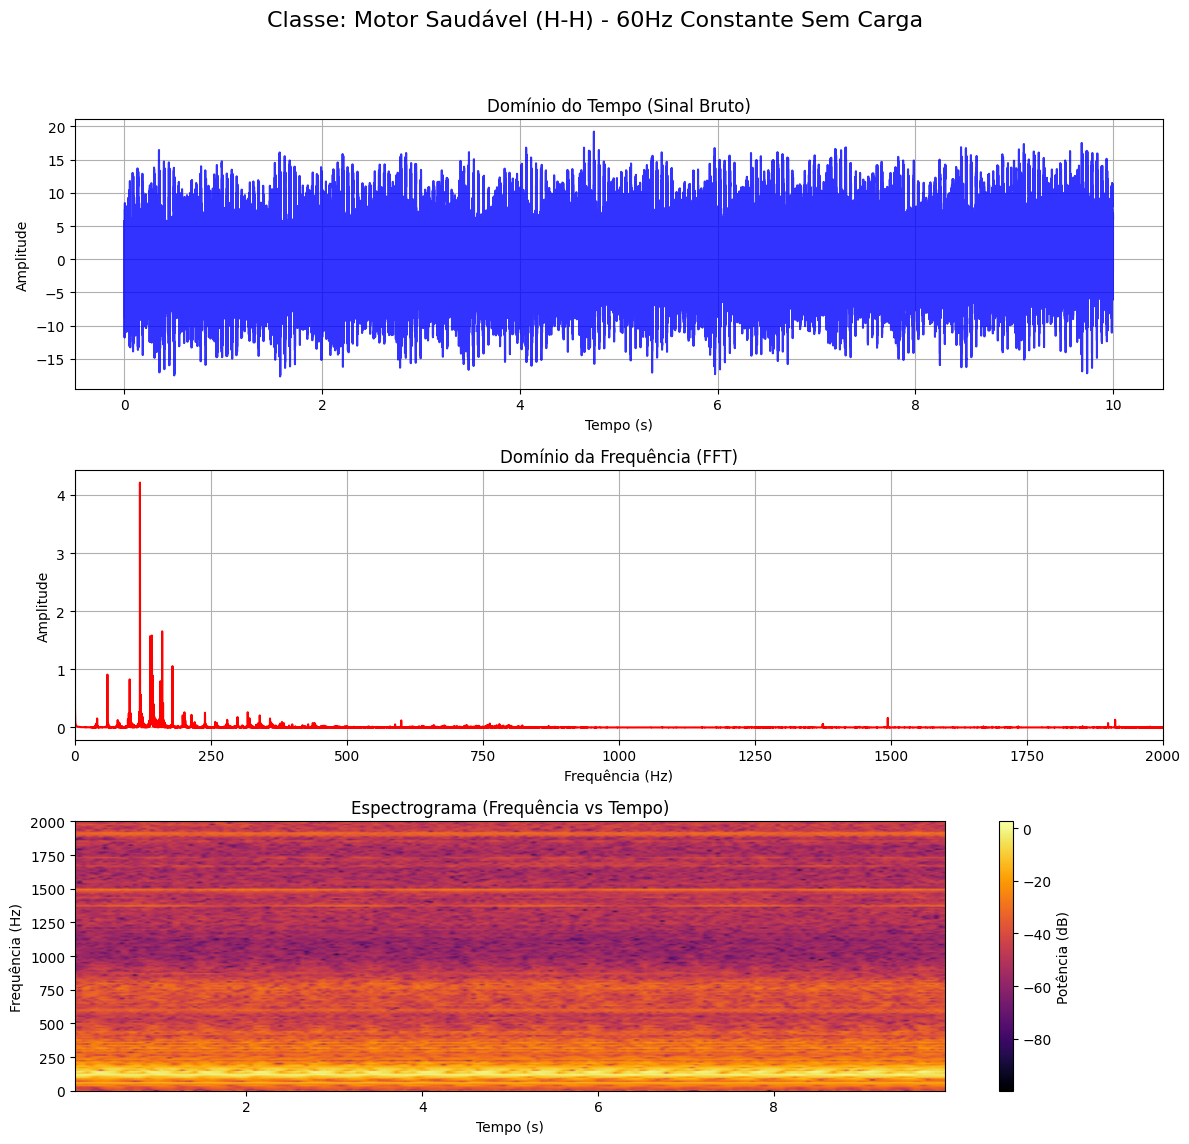

In [50]:
sinal_saudavel = carregar_sinal(f1)
plot_analise_completa(sinal_saudavel, FS, titulo="Classe: Motor Saudável (H-H) - 60Hz Constante Sem Carga")

### Desbalanceamento do Rotor

In [51]:
f2 = os.path.join(file_path, condition_1, 'R_U_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f2)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,18.322319,0.445362,5.974431,1.654283,27.501870
1,18.290079,0.420369,3.846597,9.746501,27.370331
2,18.805918,0.407873,1.202924,10.101141,27.238792
3,18.709198,0.396363,0.945005,5.716512,27.337446
4,18.096640,0.384854,1.299644,7.360748,27.370331



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


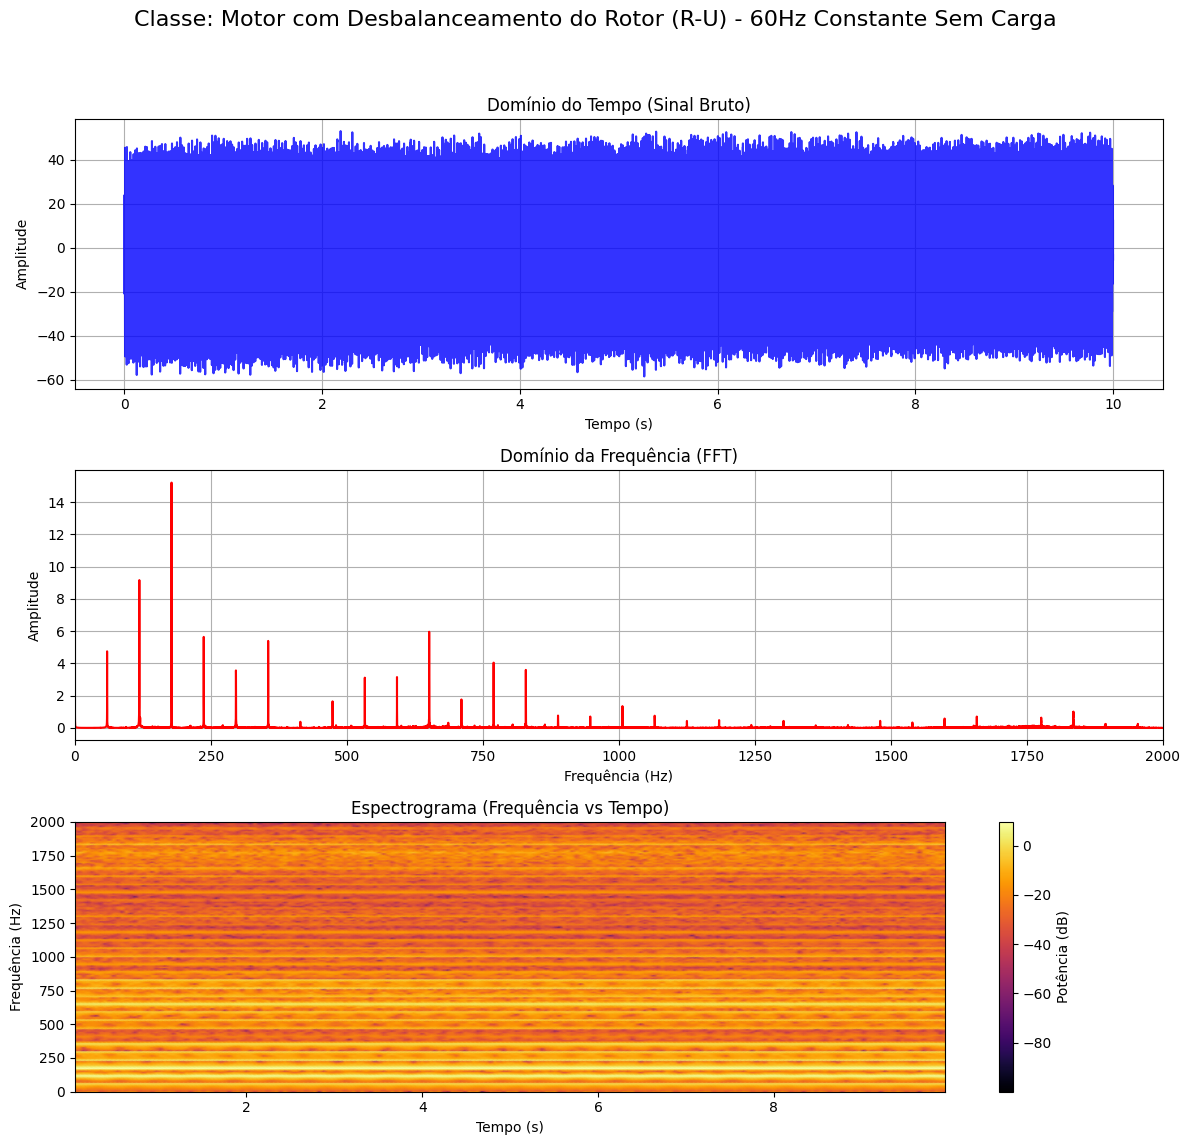

In [52]:
sinal = carregar_sinal(f2)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Desbalanceamento do Rotor (R-U) - 60Hz Constante Sem Carga")

### Desalinhamento do Rotor

In [53]:
f3 = os.path.join(file_path, condition_1, 'R_M_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f3)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,35.151557,-0.129792,-6.953773,-2.053307,32.927848
1,34.055400,-0.133738,-1.537468,-2.504666,32.993618
2,33.797481,-0.129792,-3.536343,2.299081,32.993618
3,33.152682,-0.131108,-6.051056,-4.858179,32.960733
4,33.346122,-0.125846,-3.149464,-10.145524,33.092272



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


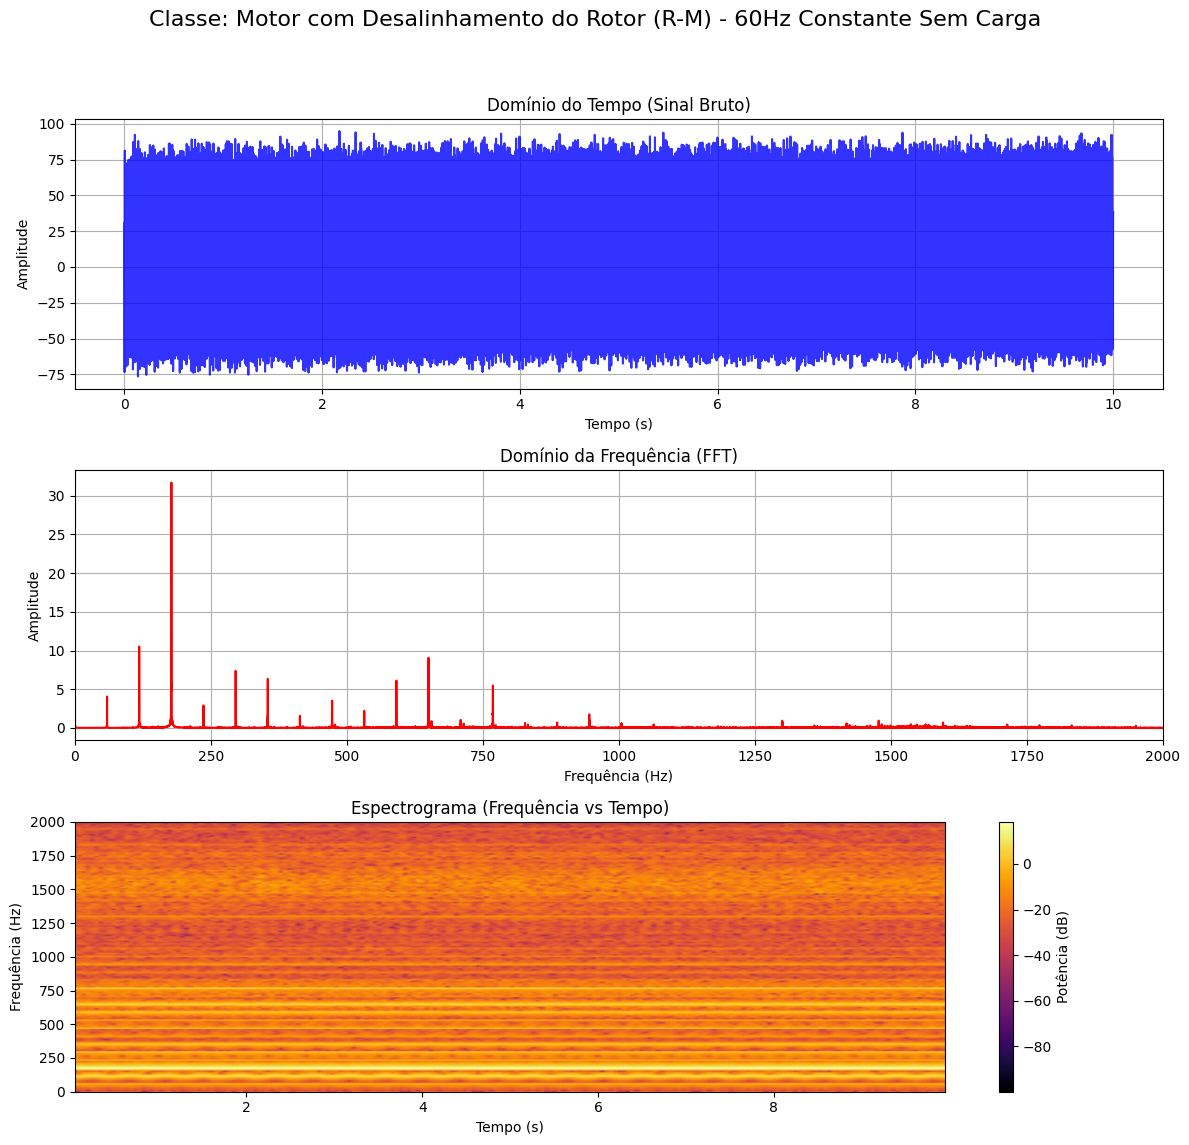

In [54]:
sinal = carregar_sinal(f3)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Desalinhamento do Rotor (R-M) - 60Hz Constante Sem Carga")

### Falha no Enrolamento do Estator

In [55]:
f4 = os.path.join(file_path, condition_1, 'S_W_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f4)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,13.454092,0.085932,0.010048,10.391300,40.392680
1,15.968805,0.098757,2.557001,11.713136,40.524219
2,16.323444,0.104676,-4.632500,5.684272,40.195372
3,15.001608,0.106978,-6.244495,5.200674,40.359795
4,12.873773,0.104018,-1.376269,9.875461,40.425565



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


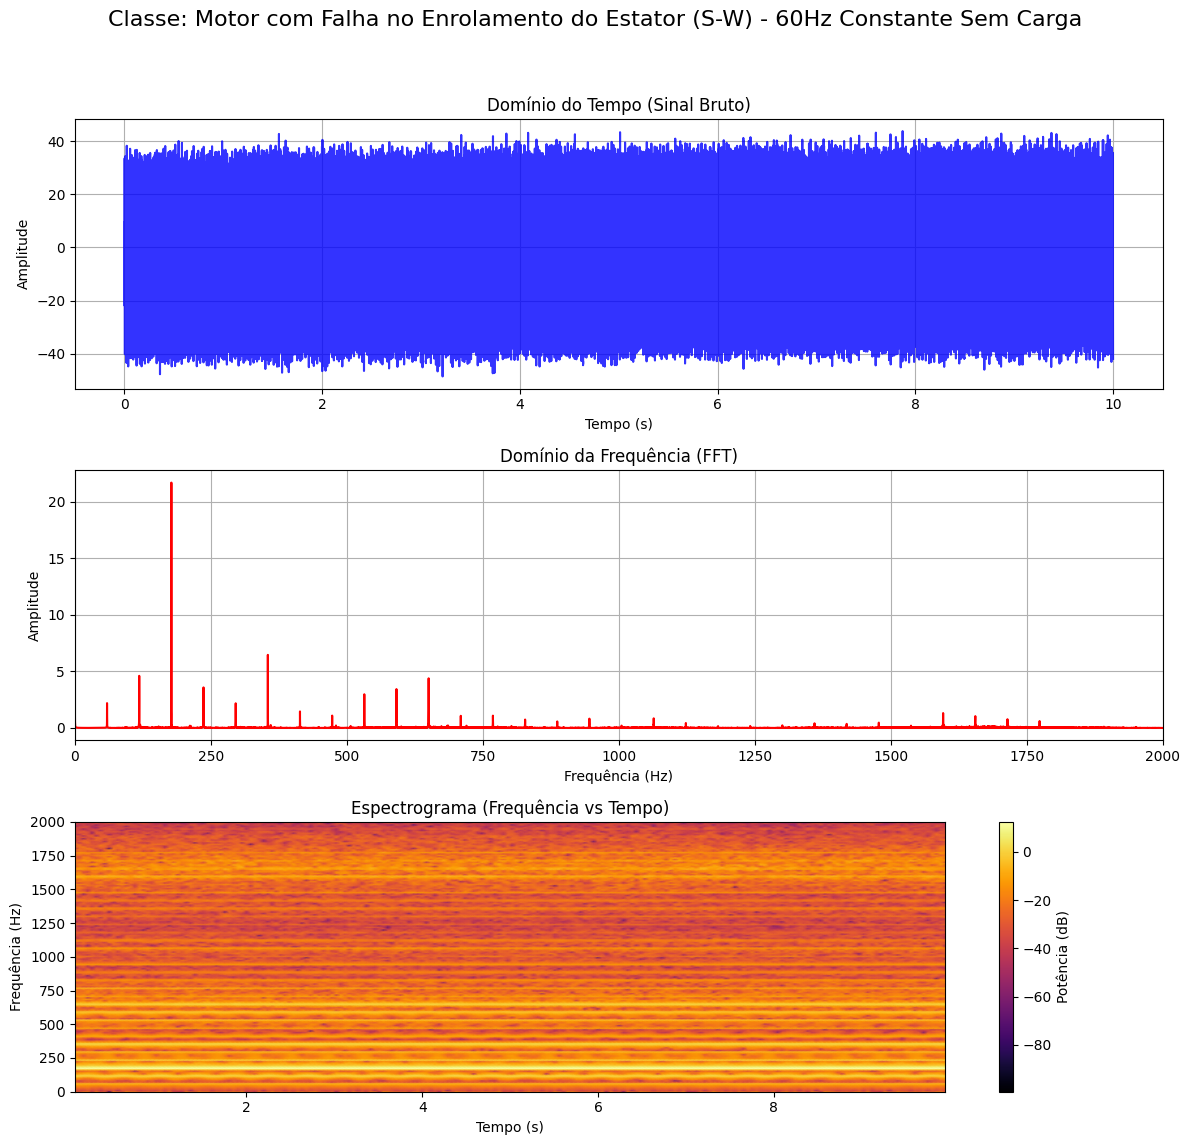

In [56]:
sinal = carregar_sinal(f4)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Falha no Enrolamento do Estator (S-W) - 60Hz Constante Sem Carga")

### Desequilíbrio de Tensão e Falta de Fase

In [57]:
f5 = os.path.join(file_path, condition_1, 'V_U_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f5)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,-46.318699,0.208920,18.257839,-15.948708,32.237269
1,-47.253656,0.205961,20.933753,-17.335024,32.434578
2,-47.737255,0.169788,32.024285,-12.434558,32.434578
3,-46.899017,0.141178,31.959805,-7.405132,32.401693
4,-44.738944,0.122105,32.765803,-7.598572,32.303039



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


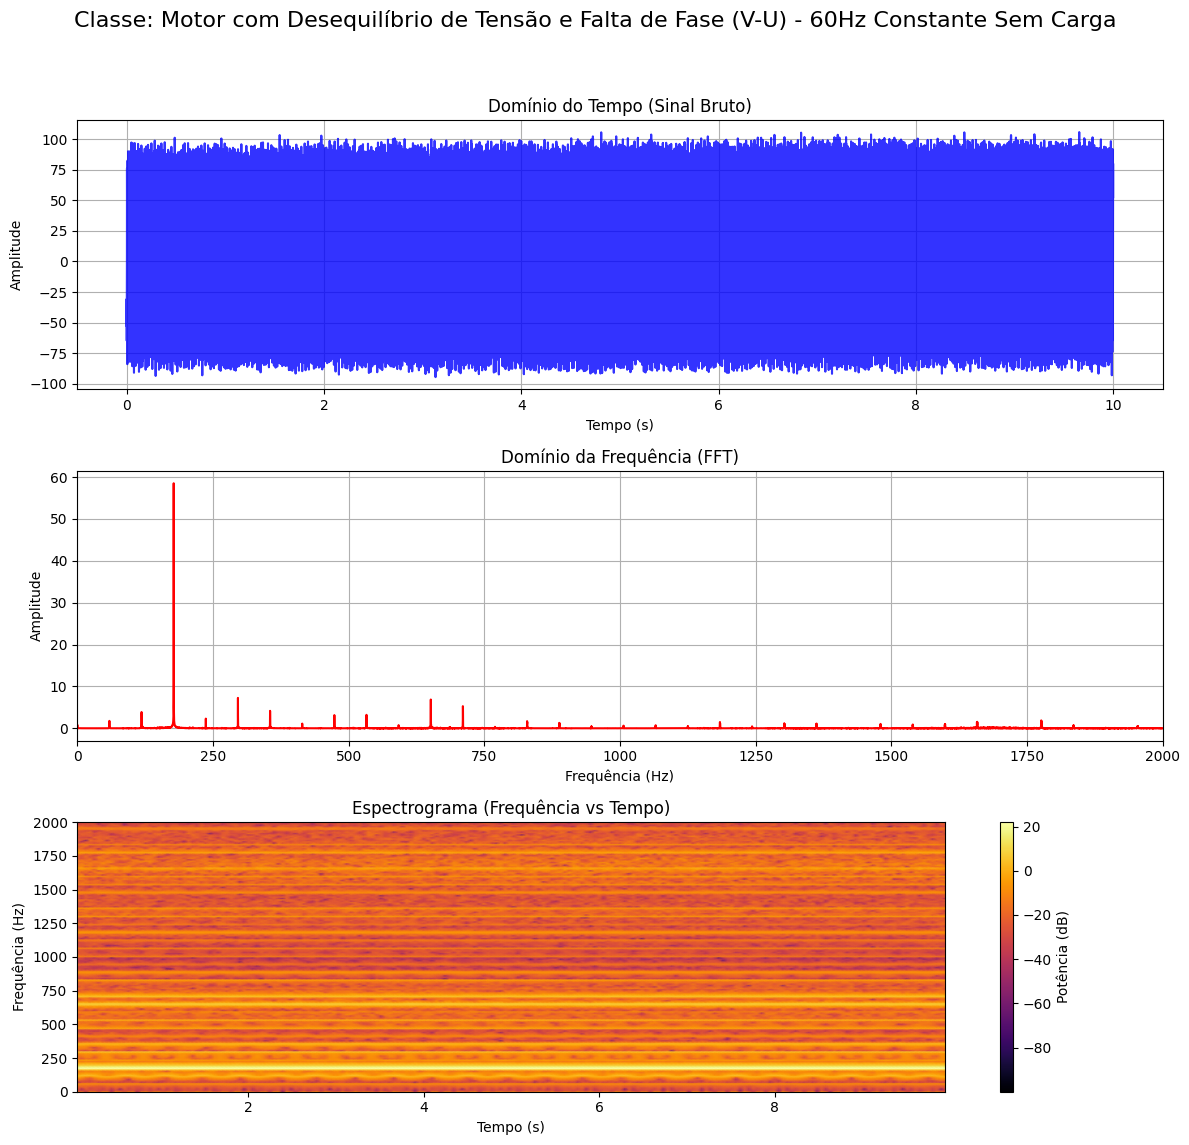

In [58]:
sinal = carregar_sinal(f5)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Desequilíbrio de Tensão e Falta de Fase (V-U) - 60Hz Constante Sem Carga")

### Rotor Empenado

In [59]:
f6 = os.path.join(file_path, condition_1, 'B_R_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f6)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,33.023722,0.478575,-19.333898,7.102828,34.440546
1,31.186047,0.434181,-19.204939,7.521947,34.473430
2,28.961492,0.371700,-10.596883,12.777054,34.374776
3,27.123817,0.317769,-7.405132,5.587553,34.506315
4,24.834783,0.288501,-14.530152,-0.957150,34.572084



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


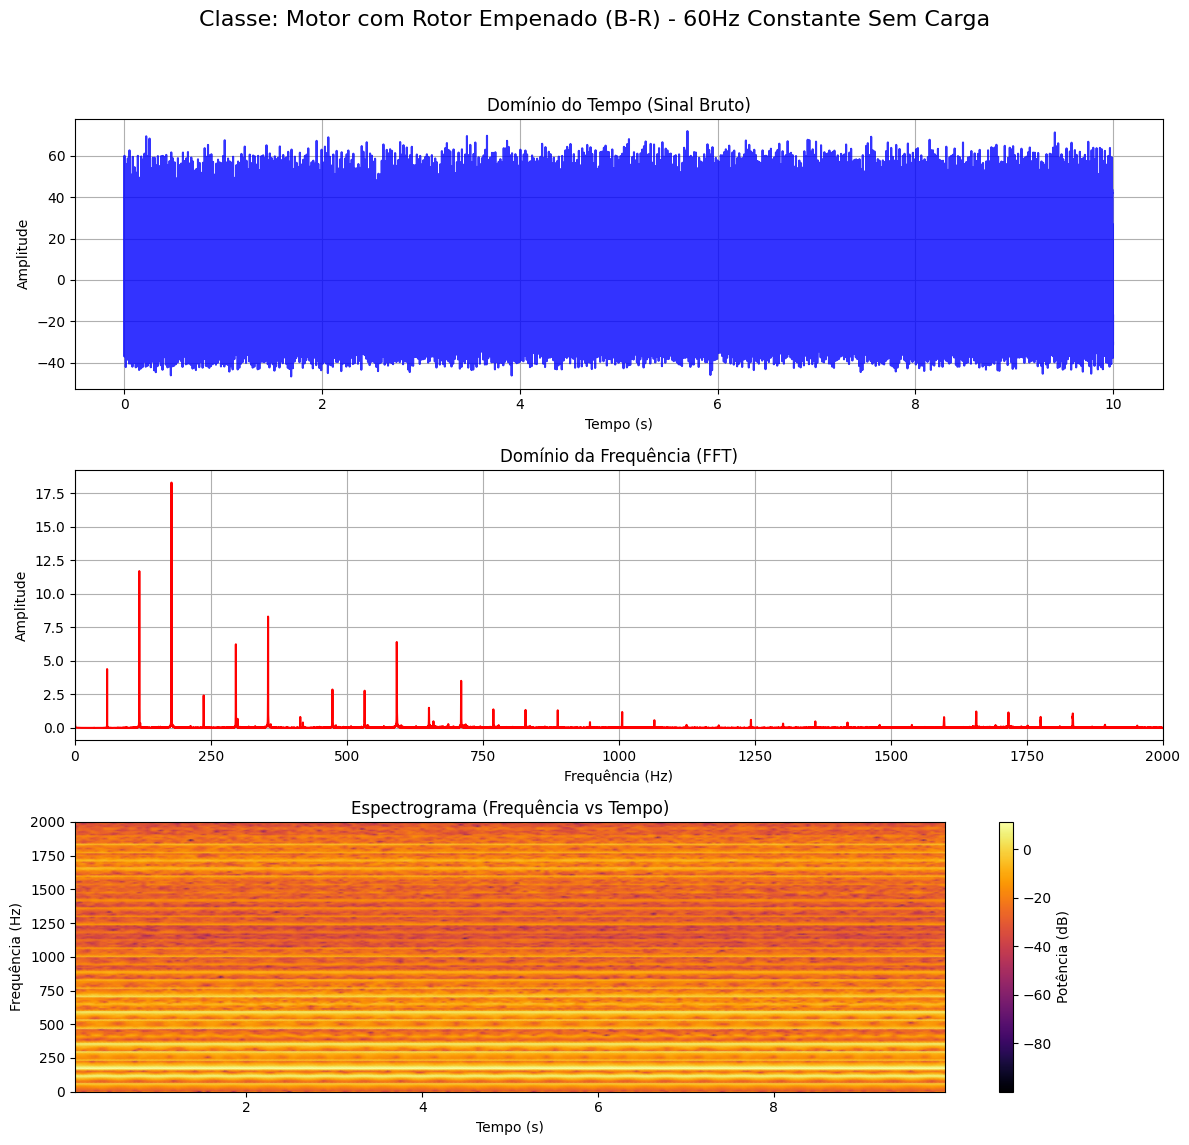

In [60]:
sinal = carregar_sinal(f6)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Rotor Empenado (B-R) - 60Hz Constante Sem Carga")

### Barras do Rotor Quebradas

In [61]:
f7 = os.path.join(file_path, condition_1, 'K_A_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f7)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,-74.786531,-0.294216,7.392988,18.547999,27.468985
1,-67.306875,-0.430687,9.907701,13.389612,27.501870
2,-58.731061,-0.562884,4.040037,12.648094,27.732063
3,-50.026288,-0.665155,5.490833,13.679771,27.764947
4,-41.547193,-0.757232,-0.602511,12.938253,27.732063



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


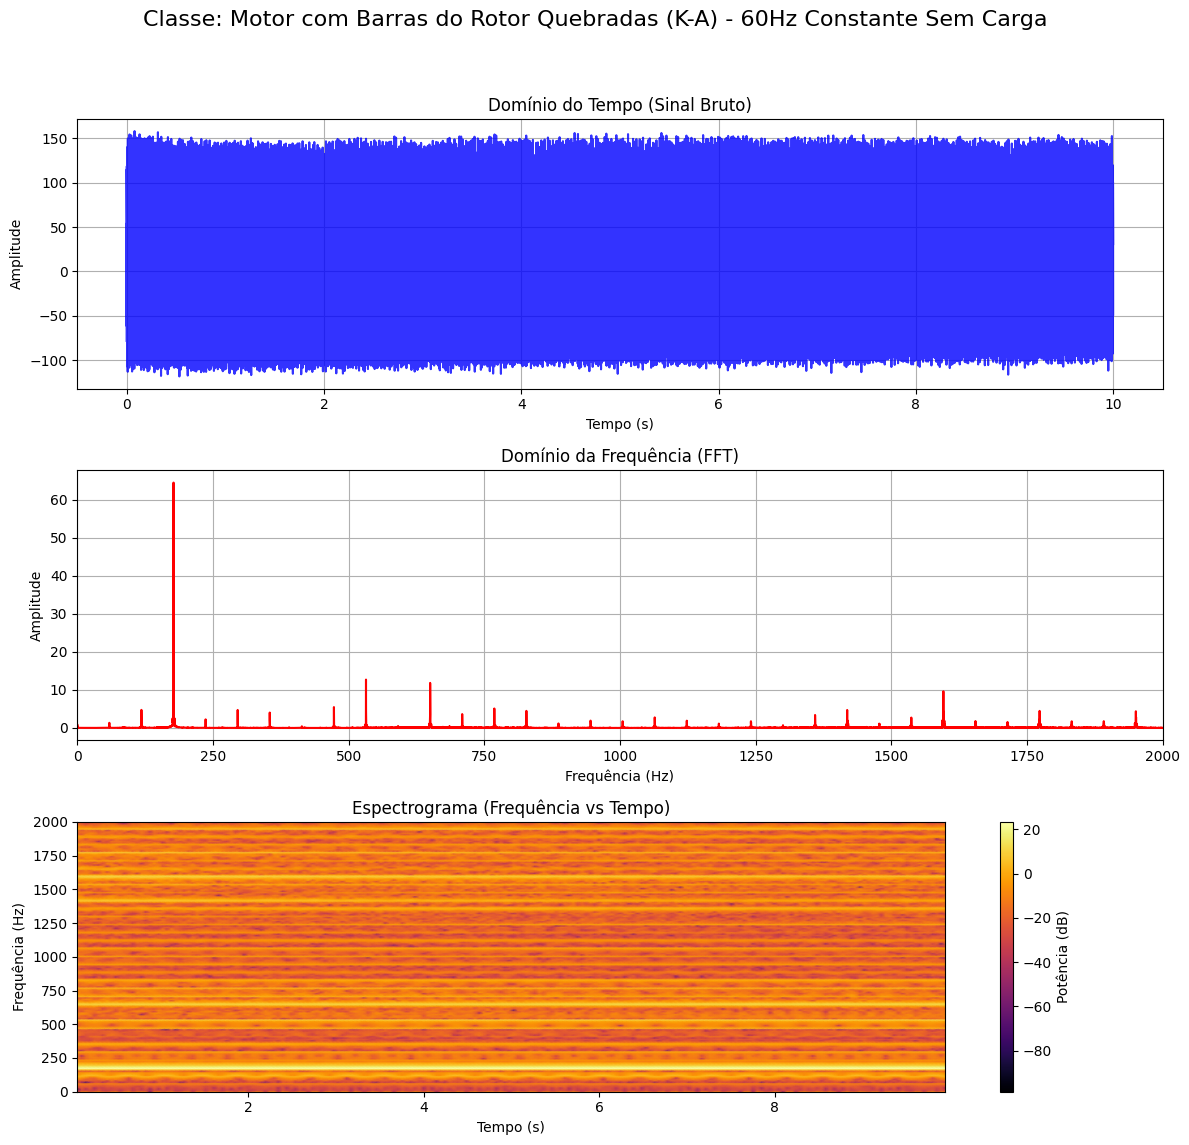

In [62]:
sinal = carregar_sinal(f7)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Barras do Rotor Quebradas (K-A) - 60Hz Constante Sem Carga")

### Rolamentos Defeituosos

In [63]:
f8 = os.path.join(file_path, condition_1, 'F_B_4_0.csv')

# Lê o arquivo CSV
df_sinal = pd.read_csv(f8)

# Exibe as 5 primeiras linhas para entender quais sensores estão presentes nas colunas
display(df_sinal.head())

# Mostra informações sobre o tamanho do dataset e os tipos de dados
print("\nInformações do Dataset:")
df_sinal.info()

,Accelerometer 1 (m/s^2),Microphone (V),Accelerometer 2 (m/s^2),Accelerometer 3 (m/s^2),Temperature (Celsius)
0,-50.509886,-0.148536,9.262903,-2.407946,32.204385
1,-43.771747,-0.157415,1.847723,2.299081,32.171500
2,-34.389935,-0.165636,-5.857616,0.171247,32.105730
3,-41.611673,-0.184710,1.331884,0.396927,32.204385
4,-43.932946,-0.156758,4.781555,3.201799,32.270154



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420000 entries, 0 to 419999
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Accelerometer 1 (m/s^2)  420000 non-null  float64
 1   Microphone (V)           420000 non-null  float64
 2   Accelerometer 2 (m/s^2)  420000 non-null  float64
 3   Accelerometer 3 (m/s^2)  420000 non-null  float64
 4   Temperature (Celsius)    420000 non-null  float64
dtypes: float64(5)
memory usage: 16.0 MB


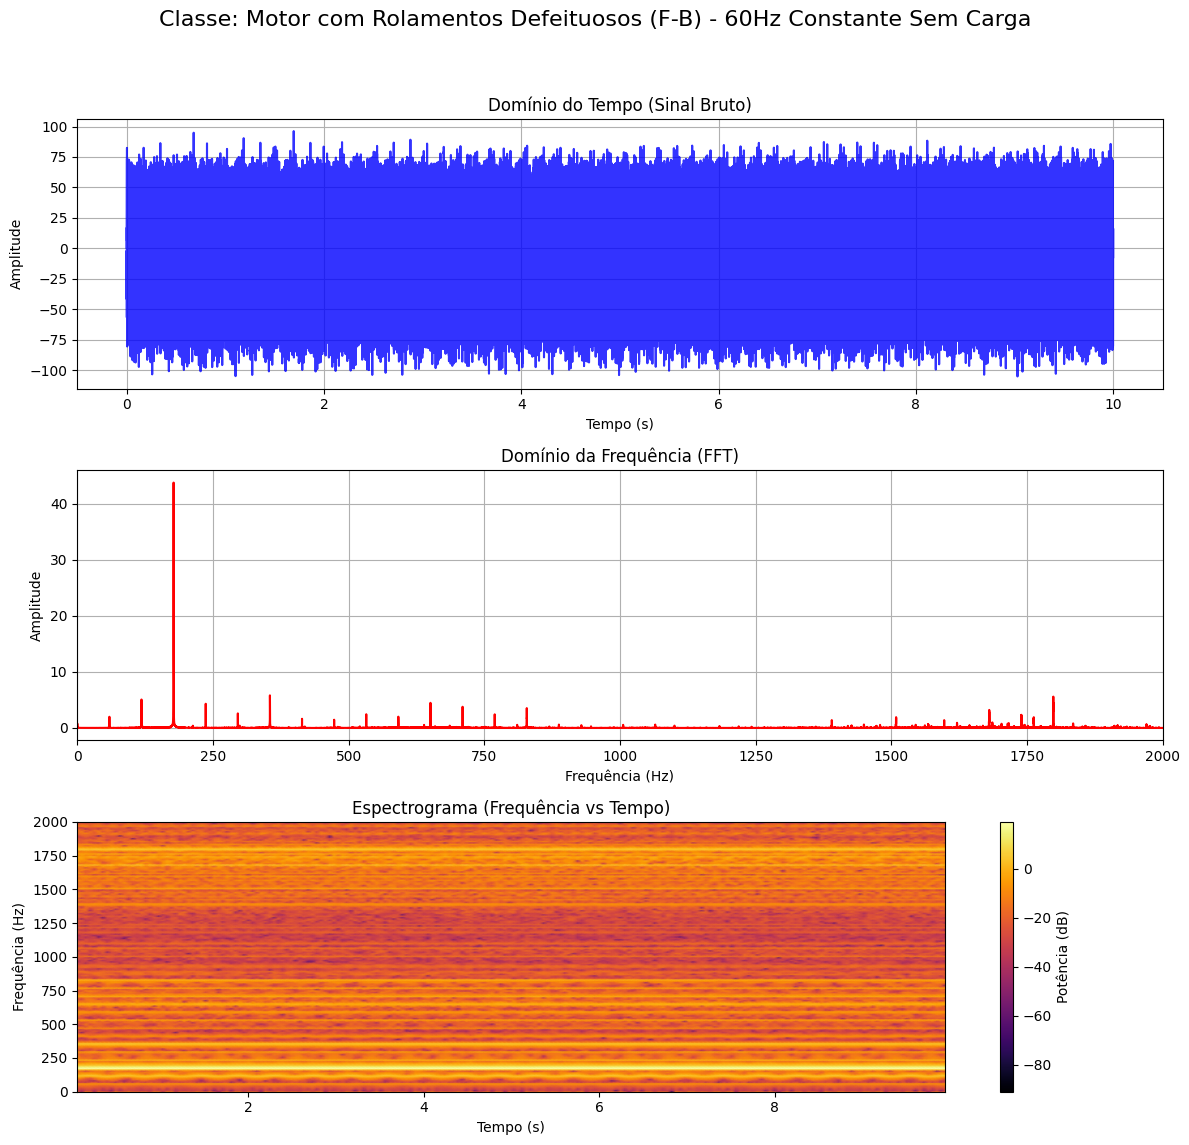

In [64]:
sinal = carregar_sinal(f8)
plot_analise_completa(sinal, FS, titulo="Classe: Motor com Rolamentos Defeituosos (F-B) - 60Hz Constante Sem Carga")

### Resumo Quantitativo das Classes (60 Hz constante, sem carga)

In [65]:
# Resumo quantitativo das classes a 60 Hz constante, sem carga (base numérica da interpretação dos gráficos)
linhas_eda = []
for cls in ['H_H', 'R_U', 'R_M', 'S_W', 'V_U', 'B_R', 'K_A', 'F_B']:
    sinal = carregar_sinal(os.path.join(file_path, condition_1, f'{cls}_4_0.csv'))
    n = len(sinal)
    espectro = np.abs(rfft(sinal))
    amplitude = 2.0 / n * espectro
    potencia = espectro**2
    xf = rfftfreq(n, 1 / FS)
    linhas_eda.append({
        'Classe': cls.replace('_', '-'),
        'RMS (m/s²)': np.sqrt(np.mean(sinal**2)),
        'Pico da FFT (Hz)': xf[np.argmax(amplitude)],
        'Amplitude 1x fr (m/s²)': amplitude[(xf >= 59) & (xf <= 61)].max(),
        'Amplitude ~3x fr, 170-185 Hz (m/s²)': amplitude[(xf >= 170) & (xf <= 185)].max(),
        'Energia acima de 2 kHz (%)': 100 * potencia[xf > 2000].sum() / potencia.sum(),
        # Valor absoluto: a fração relativa fica alta em sinais com pouca energia em baixa frequência (caso do H-H)
        'RMS acima de 2 kHz (m/s²)': np.sqrt(np.mean(sinal**2) * potencia[xf > 2000].sum() / potencia.sum())
    })

df_eda = pd.DataFrame(linhas_eda).set_index('Classe')
df_eda.insert(1, 'RMS / RMS do H-H', df_eda['RMS (m/s²)'] / df_eda.loc['H-H', 'RMS (m/s²)'])
display(df_eda.round(2))

,RMS (m/s²),RMS / RMS do H-H,Pico da FFT (Hz),Amplitude 1x fr (m/s²),"Amplitude ~3x fr, 170-185 Hz (m/s²)",Energia acima de 2 kHz (%),RMS acima de 2 kHz (m/s²)
Classe,,,,,,,
H-H,5.06,1.00,119.6,0.91,1.05,10.41,1.63
R-U,18.96,3.75,177.7,4.75,15.22,0.15,0.73
R-M,36.13,7.14,177.4,4.06,31.70,0.09,1.08
S-W,18.53,3.66,177.4,2.20,21.71,0.17,0.76
V-U,51.05,10.09,177.7,1.77,58.52,0.09,1.56
B-R,22.29,4.40,177.6,4.38,18.28,0.26,1.15
K-A,61.37,12.13,177.4,1.35,64.46,0.70,5.13
F-B,38.07,7.52,177.5,2.00,43.80,1.33,4.38


### Interpretação dos Gráficos (60 Hz constante, sem carga)
Os valores citados abaixo estão na tabela do Resumo Quantitativo das Classes.
- **Motor saudável (H-H):** RMS de 5,1 m/s². O maior pico da FFT está em ~120 Hz (2× fr), seguido de componentes entre 140 e 160 Hz e do 1× fr (0,91 m/s²). O espectrograma mostra linhas horizontais estáveis, como esperado em velocidade constante.
- **Todos os motores com falha** têm vibração global muito maior que a do saudável (RMS de 18,5 m/s² no S-W a 61,4 m/s² no K-A, ou seja, de 3,7 a 12,1 vezes o RMS do H-H) e o maior pico da FFT em ~177,5 Hz (3× fr), componente que no motor saudável é pequena (1,05 m/s²).
- **Desbalanceamento (R-U), desalinhamento (R-M) e rotor empenado (B-R):** amplitude em 1× fr entre 4,1 e 4,8 m/s², cerca de 5 vezes a do motor saudável, coerente com falhas mecânicas ligadas à rotação do eixo.
- **Desequilíbrio de tensão (V-U) e barras quebradas (K-A):** os maiores níveis de vibração (RMS de 51,1 e 61,4 m/s²), concentrados no pico de ~177,5 Hz.
- **Rolamento (F-B):** entre as classes com falha, é a de maior fração de energia acima de 2 kHz (1,33%, contra 0,09% a 0,70% nas demais), conteúdo de alta frequência típico de impactos em rolamentos. Essa fração relativa, porém, deve ser lida com cuidado: no H-H ela é de 10,4%, porque a energia total do motor saudável é baixa, e em valor absoluto o conteúdo acima de 2 kHz do F-B (RMS de 4,4 m/s²) fica próximo ao do K-A (5,1 m/s²). O indício mais específico de defeito de rolamento é o espectro de envelope (Análise Complementar).

Como cada classe corresponde a um motor físico diferente (SEHRI; DUMOND, 2024), parte dessas diferenças, em especial o nível global de vibração e o pico em 3× fr comum aos 7 motores com falha, pode refletir diferenças entre os motores, e não apenas a falha. Isso torna a separação entre saudável e falha relativamente fácil, inclusive para um limiar simples de RMS, e é uma limitação importante para generalizar os resultados.

### Análise Complementar: Efeito da Velocidade e Espectro de Envelope
Duas verificações físicas apoiam a discussão dos resultados:
1. **Efeito da velocidade no desbalanceamento:** a força de desbalanceamento é proporcional a $m \cdot e \cdot \omega^2$. Comparamos a amplitude em 1× fr do motor saudável (H-H) e do motor com desbalanceamento (R-U) a 15 Hz e a 60 Hz.
2. **Espectro de envelope do rolamento:** o sinal é filtrado em 2–10 kHz e demodulado pela Transformada de Hilbert (RANDALL; ANTONI, 2011). Defeitos de rolamento geram impactos periódicos que aparecem como picos no espectro do envelope. As frequências teóricas de defeito nas pistas externa (BPFO) e interna (BPFI) são calculadas para a geometria padrão do rolamento 6205 (9 esferas, diâmetro da esfera de 7,94 mm e diâmetro primitivo de 39,04 mm), já que o artigo do dataset informa apenas o modelo do rolamento.

In [ ]:
# 1. Efeito da velocidade no desbalanceamento: amplitude em 1x fr para H-H e R-U a 15 Hz e a 60 Hz (sem carga)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, (speed_code, fr_nominal) in zip(axs, [('1', 15), ('4', 60)]):
    for cls, cor in [('H_H', 'b'), ('R_U', 'r')]:
        sinal = carregar_sinal(os.path.join(file_path, condition_1, f'{cls}_{speed_code}_0.csv'))
        n = len(sinal)
        amplitude = 2.0 / n * np.abs(rfft(sinal))
        xf = rfftfreq(n, 1 / FS)
        amplitude_1x = amplitude[(xf >= fr_nominal - 1) & (xf <= fr_nominal + 1)].max()
        print(f"{cls.replace('_', '-')} a {fr_nominal} Hz: amplitude em 1x fr = {amplitude_1x:.3f} m/s²")
        ax.plot(xf, amplitude, color=cor, alpha=0.7, label=cls.replace('_', '-'))
    for k in (1, 2, 3):
        ax.axvline(k * fr_nominal, color='gray', linestyle='--', lw=0.8)
    ax.set_xlim([0, 4 * fr_nominal])
    ax.set_title(f"Espectro H-H x R-U a {fr_nominal} Hz (Sem Carga)")
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Amplitude (m/s²)")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

# 2. Espectro de envelope H-H x F-B a 60 Hz (rolamento 6205: 9 esferas, d = 7,94 mm, D = 39,04 mm)
N_ESFERAS, D_ESFERA, D_PRIMITIVO = 9, 7.94, 39.04
BPFO_ORDEM = N_ESFERAS / 2 * (1 - D_ESFERA / D_PRIMITIVO)
BPFI_ORDEM = N_ESFERAS / 2 * (1 + D_ESFERA / D_PRIMITIVO)
FILTRO_ENVELOPE = signal.butter(4, [2000, 10000], btype='bandpass', fs=FS, output='sos')

def espectro_envelope(sinal, fs):
    """Filtra o sinal em 2-10 kHz, demodula pela Transformada de Hilbert e retorna o espectro do envelope."""
    envelope = np.abs(signal.hilbert(signal.sosfiltfilt(FILTRO_ENVELOPE, sinal)))
    envelope = envelope - np.mean(envelope)
    n = len(envelope)
    return rfftfreq(n, 1 / fs), 2.0 / n * np.abs(rfft(envelope))

print(f"\nBPFO = {BPFO_ORDEM:.3f} x fr | BPFI = {BPFI_ORDEM:.3f} x fr")

fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (cls, cor) in zip(axs, [('H_H', 'b'), ('F_B', 'r')]):
    xf, env = espectro_envelope(carregar_sinal(os.path.join(file_path, condition_1, f'{cls}_4_0.csv')), FS)
    ax.plot(xf, env, color=cor)
    for ordem, nome, estilo in [(1, '1x fr', ':'), (BPFO_ORDEM, 'BPFO teórica', '--'), (BPFI_ORDEM, 'BPFI teórica', '-.')]:
        ax.axvline(ordem * 60, color='gray', linestyle=estilo, label=nome)
    ax.set_xlim([0, 500])
    ax.set_title(f"Espectro de Envelope (2-10 kHz) - {cls.replace('_', '-')} a 60 Hz Sem Carga")
    ax.set_ylabel("Amplitude (m/s²)")
    ax.legend()
    ax.grid(True)
axs[1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.show()

# 3. Maior pico não síncrono do envelope (exclui múltiplos inteiros de fr) nas velocidades constantes de 30, 45 e 60 Hz
for cls in ['H_H', 'F_B']:
    for condicao, carga in [(condition_1, '0'), (condition_2, '1')]:
        for speed_code, fr_nominal in [('2', 30), ('3', 45), ('4', 60)]:
            xf, env = espectro_envelope(carregar_sinal(os.path.join(file_path, condicao, f'{cls}_{speed_code}_{carga}.csv')), FS)
            ordens = xf / fr_nominal
            faixa = (ordens > 1.5) & (ordens < 8) & (np.abs(ordens - np.round(ordens)) > 0.1)
            ordem_pico = ordens[faixa][np.argmax(env[faixa])]
            print(f"{cls.replace('_', '-')} | carga {carga} | {fr_nominal} Hz: maior pico não síncrono do envelope em {ordem_pico:.2f} x fr")

H-H a 15 Hz: amplitude em 1x fr = 0.072 m/s²
R-U a 15 Hz: amplitude em 1x fr = 0.153 m/s²
H-H a 60 Hz: amplitude em 1x fr = 0.909 m/s²


**Efeito da velocidade:** a 60 Hz, a amplitude em 1× fr do R-U é 4,75 m/s², contra 0,91 m/s² do H-H. A 15 Hz, os valores caem para 0,153 e 0,072 m/s²: a diferença entre o motor desbalanceado e o saudável passa de 3,8 m/s² para apenas 0,08 m/s². A força de desbalanceamento cresce com ω², então a 15 Hz ela é cerca de 1/16 da força a 60 Hz. Na prática, a amplitude em 1× fr do R-U caiu 31 vezes entre 60 e 15 Hz. Em baixa velocidade, o sinal do motor desbalanceado fica muito próximo do sinal saudável, o que antecipa a dificuldade de detecção do R-U a 15 Hz vista nos resultados.

**Espectro de envelope:** o F-B tem picos de envelope que não aparecem no H-H. O maior pico não síncrono fica em 4,83 a 4,89× fr a 45 e 60 Hz, com e sem carga (a 30 Hz, o maior pico não síncrono fica em 1,85 a 1,86× fr). No H-H, os picos de envelope são harmônicos da rotação, e o maior pico não síncrono muda de ordem a cada condição. Duas conclusões:
1. O F-B tem, de fato, uma modulação não síncrona e repetitiva, típica de defeitos de rolamento (RANDALL; ANTONI, 2011), o que apoia a explicação física para o bom desempenho nessa classe.
2. Esse componente não coincide com as frequências teóricas BPFO (3,585× fr) e BPFI (5,415× fr) calculadas para a geometria padrão do 6205. A geometria real do rolamento, ou a localização do defeito, deve ser diferente da assumida; portanto, as features `envelope_bpfo_rel` e `envelope_bpfi_rel` medem frequências que não são as do defeito. Usar a geometria real é uma melhoria clara para trabalhos futuros.

# Mapeamento dos Arquivos e Divisão por Arquivo

A seguir será realizada a extração e organização dos dados para treinamento dos modelos de detecção de anomalias e de diagnóstico de falhas.

**Metodologia de divisão, janelamento e treino:**
- **Divisão por arquivo, antes do janelamento:** cada arquivo (uma combinação de classe, velocidade e carga) é a unidade da divisão. A divisão usa `StratifiedKFold` com 4 folds sobre a tabela de arquivos, estratificada por classe e carga: cada fold de teste tem 4 arquivos de cada classe (2 sem carga e 2 com carga, 25% dos dados), e nenhum arquivo aparece ao mesmo tempo em treino e teste. Como cada arquivo é o seu próprio grupo, uma divisão agrupada (`StratifiedGroupKFold`) não é necessária: dividir a tabela de arquivos já impede o leakage, e a estratificação por carga garante folds equilibrados. O fold 0 é usado nas análises detalhadas (curvas ROC e matrizes de confusão), e os 4 folds são usados na validação cruzada, que reporta média ± desvio das métricas.
- **Janelas de 1 s (42.000 amostras):** na menor rotação (15 Hz), a janela contém 15 rotações completas, e a resolução espectral de 1 Hz é suficiente para separar os harmônicos 1×, 2× e 3× da rotação.
- **Sobreposição de 50%:** gera 19 janelas por arquivo de 10 s. As janelas de um mesmo arquivo são correlacionadas; por isso, além das métricas por janela, também são reportadas métricas agregadas por arquivo.
- **Sensores:** são janelados os 3 acelerômetros e o microfone. O Acelerômetro 1 (drive end do motor) é o sensor dos modelos principais; os demais sensores entram no estudo de fusão de sensores (ablação de features).
- **Padronização:** o `StandardScaler` é ajustado apenas com os dados de treino.
- **Detecção (novelty detection):** os detectores são treinados somente com janelas saudáveis (H-H) do treino. Os parâmetros `contamination = 0.05` (Isolation Forest e LOF) e `nu = 0.05` (One-Class SVM) definem o limiar de decisão para que cerca de 5% das janelas saudáveis do treino fiquem acima dele. O `n_neighbors = 20` do LOF segue o valor sugerido por Breunig et al. (2000). A sensibilidade a esses valores é analisada mais adiante.
- **Diagnóstico:** os classificadores são treinados com todas as classes do treino e avaliados no mesmo conjunto de teste completo.
- **Reprodutibilidade:** as seeds são fixas e as versões das bibliotecas usadas estão impressas no início do notebook.

É realizada uma validação após a criação das janelas para garantir que não houve leakage entre os dados de teste e treino.

In [ ]:
# 1. Localizar os arquivos CSV de sinais em ordem fixa (a pasta 1_Time contém apenas o eixo de tempo e não é usada)
csv_files = sorted(glob.glob(os.path.join(file_path, '**/*.csv'), recursive=True))

# 2. Criar tabela de metadados dos arquivos
records = []

for filepath in csv_files:
    filename = os.path.basename(filepath)
    name_no_ext = os.path.splitext(filename)[0]

    # Aceita apenas o padrão CLASSE_SUBCLASSE_VELOCIDADE_CARGA (ex: R_U_1_0.csv)
    if not re.fullmatch(r'[A-Z]_[A-Z]_\d_\d', name_no_ext):
        continue

    # Extrai a classe de saúde a partir do nome do arquivo (ex: H-H, R-U, R-M, etc.)
    parts = re.split(r'[-_]', name_no_ext)

    health_class = f"{parts[0]}-{parts[1]}" # Ex: 'R-U'
    speed_code = parts[2]                    # Ex: '1'
    load_code = parts[3]                     # Ex: '0'

    records.append({
        'file_id': name_no_ext,              # ID único por registro/arquivo
        'filepath': filepath,
        'health_class': health_class,
        'speed_code': speed_code,
        'load_code': load_code
    })

df_meta = pd.DataFrame(records)

print(f"Total de arquivos mapeados: {len(df_meta)} | Classes: {df_meta['health_class'].nunique()}")
print("\nDistribuição de arquivos por Classe de Saúde:")
print(df_meta['health_class'].value_counts())

# 3. Divisão Treino e Teste NÍVEL DE ARQUIVO (Evitando Data Leakage)
# Cada linha de df_meta é um arquivo: dividir df_meta já impede que janelas de um mesmo arquivo fiquem em treino e teste.
# A estratificação por classe + carga garante 4 arquivos de cada classe por fold (2 sem carga e 2 com carga)
estrato = df_meta['health_class'] + '_' + df_meta['load_code']
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
folds = list(skf.split(df_meta, estrato))

# O fold 0 é usado nas análises detalhadas; os 4 folds são usados na validação cruzada
train_idx, test_idx = folds[0]

df_train_files = df_meta.iloc[train_idx].reset_index(drop=True)
df_test_files = df_meta.iloc[test_idx].reset_index(drop=True)

print(f"\n--- Resumo da Divisão de Arquivos ---")
print(f"Arquivos de Treino: {len(df_train_files)} ({len(df_train_files)/len(df_meta):.1%})")
print(f"Arquivos de Teste:  {len(df_test_files)} ({len(df_test_files)/len(df_meta):.1%})")
print("\nArquivos de teste por classe e carga (0 = sem carga, 1 = com carga):")
display(pd.crosstab(df_test_files['health_class'], df_test_files['load_code']))

*Função* de Janelamento Pós-Divisão

In [ ]:
# Perfil de velocidade de cada código (Hz no início e no fim do arquivo)
PERFIS_VELOCIDADE = {'1': (15, 15), '2': (30, 30), '3': (45, 45), '4': (60, 60),
                     '5': (15, 45), '6': (30, 60), '7': (45, 15), '8': (60, 30)}
SENSORES = ['acc1', 'acc2', 'acc3', 'mic']

def gerar_janelas_temporais(df_files, window_size=42000, overlap=0.5, col_sensores=[0, 2, 3, 1]):
    """
    Fatia o sinal de cada arquivo em janelas com sobreposição.

    Parâmetros:
    - df_files: DataFrame contendo o mapeamento dos arquivos (Treino ou Teste)
    - window_size: Tamanho da janela em amostras (42.000 = 1 segundo a 42 kHz)
    - overlap: Porcentagem de sobreposição entre janelas (0.5 = 50%)
    - col_sensores: Índices das colunas dos sensores (0 = Acelerômetro 1, 2 = Acelerômetro 2, 3 = Acelerômetro 3, 1 = Microfone)

    Retorna também a rotação nominal (Hz) no centro de cada janela, interpolada linearmente nas rampas.
    """
    step = int(window_size * (1 - overlap))

    X_windows = []
    y_labels = []
    file_ids = []
    fr_windows = []

    for idx, row in df_files.iterrows():
        # Lê o CSV e extrai as colunas dos sensores
        df = pd.read_csv(row['filepath'])
        sinais = df.iloc[:, col_sensores].apply(pd.to_numeric, errors='coerce').dropna().values.T

        # Centraliza cada sinal (remove offset DC)
        sinais = sinais - sinais.mean(axis=1, keepdims=True)

        fr_inicio, fr_fim = PERFIS_VELOCIDADE[row['speed_code']]

        # Fatiamento em janelas
        n_samples = sinais.shape[1]
        for start in range(0, n_samples - window_size + 1, step):
            end = start + window_size
            window = sinais[:, start:end].astype(np.float32)

            X_windows.append(window)
            y_labels.append(row['health_class'])
            file_ids.append(row['file_id'])
            fr_windows.append(fr_inicio + (fr_fim - fr_inicio) * (start + end) / 2 / n_samples)

    return np.array(X_windows), np.array(y_labels), np.array(file_ids), np.array(fr_windows)

# -------------------------------------------------------------
# Aplicando o janelamento SEPARADAMENTE em Treino e Teste
# -------------------------------------------------------------
OVERLAP = 0.5        # 50% de sobreposição (gera 19 janelas por arquivo de 10s)

print("Gerando janelas do conjunto de TREINO...")
X_train_raw, y_train, train_file_ids, train_fr = gerar_janelas_temporais(
    df_train_files, window_size=FS, overlap=OVERLAP
)

print("Gerando janelas do conjunto de TESTE...")
X_test_raw, y_test, test_file_ids, test_fr = gerar_janelas_temporais(
    df_test_files, window_size=FS, overlap=OVERLAP
)

print("\n--- Resultado do Janelamento ---")
print(f"Shape de Treino (X_train_raw): {X_train_raw.shape}  (janelas, sensores, amostras)")
print(f"Shape de Teste  (X_test_raw):  {X_test_raw.shape}")

print("\nJanelas por classe:")
display(pd.DataFrame({'Treino': pd.Series(y_train).value_counts(),
                      'Teste': pd.Series(y_test).value_counts()}).sort_index())

Teste de Validação Anti-Leakage

In [ ]:
# Verificação de interseção entre os IDs dos arquivos de treino e teste
arquivos_treino = set(np.unique(train_file_ids))
arquivos_teste = set(np.unique(test_file_ids))

intersecao = arquivos_treino.intersection(arquivos_teste)

if len(intersecao) == 0:
    print("Nenhum arquivo de treino está presente no conjunto de teste!")
    print("Sua divisão está livre de Data Leakage.")
else:
    print(f"Foram encontrados {len(intersecao)} arquivos compartilhados entre treino e teste!")

## Pipeline de Extração de Features

Para cada janela são extraídas features nos domínios do tempo, da frequência e do envelope. A extração é feita para os 4 sensores (prefixos `acc1_`, `acc2_`, `acc3_` e `mic_`), mas os modelos principais usam apenas o Acelerômetro 1; os demais sensores entram no estudo de ablação.

1. Domínio do Tempo:

RMS (Root Mean Square): Medida da energia global da vibração ($\text{RMS} = \sqrt{\frac{1}{N}\sum x_i^2}$).

Pico a Pico e Valor de Pico: Indicadores de amplitudes extremas no sinal.

Curtose (Kurtosis): Sensível a choques e impactos (crucial para falhas de rolamento).

Assimetria (Skewness): Avalia a falta de simetria na distribuição do sinal.

Fator de Crista, Fator de Forma e Fator de Impulso: Razões estruturais que destacam variações abruptas de ruído em relação à energia média do sinal.

2. Domínio da Frequência (FFT):

Frequência de Pico: Identifica a frequência dominante na janela.

Média e Desvio Padrão Espectral: Centro de massa e dispersão do espectro, ponderados pela potência ($|X(f)|^2$).

Energia em Faixas de Frequência (Banda de Frequência): Soma da potência em bandas estratégicas ($0\text{--}100\text{ Hz}$, $100\text{--}500\text{ Hz}$, $500\text{--}2000\text{ Hz}$, $2000\text{--}10000\text{ Hz}$ e $10000\text{--}21000\text{ Hz}$, até a frequência de Nyquist), em valor absoluto e relativo à energia total. Os modelos principais usam as 4 primeiras bandas em valor absoluto; a banda de 10–21 kHz e as energias relativas entram apenas nos conjuntos da ablação.

3. Envelope do Sinal (Transformada de Hilbert):

RMS, Curtose e Fator de Crista do Envelope: Essenciais para extrair a modulação provocada por falhas em componentes rotativos (rolamento e barras do rotor) (RANDALL; ANTONI, 2011).

4. Features Físicas Normalizadas pela Rotação:

Rotação estimada: a rotação nominal da janela vem do perfil de velocidade do arquivo (interpolada nas rampas) e é refinada pelo pico do espectro entre 0,8 e 1,2 vezes esse valor.

Ordens 1×, 2× e 3×: amplitude do espectro nos harmônicos da rotação, dividida pelo RMS da janela. O 1× está ligado a desbalanceamento e rotor empenado, e o 2× a desalinhamento (RANDALL, 2011).

Envelope nas frequências de defeito do rolamento: amplitude do espectro de envelope (banda de 2–10 kHz) em BPFO e BPFI, relativa à mediana do espectro de envelope (SMITH; RANDALL, 2015).

**Conjuntos de features usados nos modelos:**
- **Detecção:** as 20 features originais do Acelerômetro 1 (tempo, frequência com as 4 bandas absolutas e envelope).
- **Diagnóstico:** as 20 features originais + as 5 features físicas (ordens 1×, 2× e 3×, BPFO e BPFI).

Esses conjuntos são comparados na seção de Ablação dos Conjuntos de Features com a fusão dos 4 sensores e com a remoção das features redundantes. Entre os conjuntos de um único sensor, as 20 features originais dão o melhor compromisso entre AUC e FPR para os detectores, e as 5 features físicas melhoram o diagnóstico do Random Forest e do Nearest Centroid. Os conjuntos sem redundantes e com fusão de sensores têm acurácia do Random Forest um pouco maior, mas a diferença fica dentro do desvio entre os folds (ver Ablação).

In [ ]:
def estimar_rotacao(janela, fr_nominal, fs=42000):
    """Refina a rotação nominal buscando o pico do espectro entre 0,8 e 1,2 vezes o valor nominal."""
    n = len(janela)
    yf = np.abs(rfft(janela))
    xf = rfftfreq(n, 1 / fs)
    faixa = (xf >= 0.8 * fr_nominal) & (xf <= 1.2 * fr_nominal)
    return xf[faixa][np.argmax(yf[faixa])]


def amplitude_em(yf, xf, freq, tolerancia):
    """Maior amplitude do espectro na faixa freq ± tolerancia (Hz)."""
    return np.max(yf[(xf >= freq - tolerancia) & (xf <= freq + tolerancia)])


def extrair_features_janela(janela, fr, fs=42000):
    """
    Extrai um dicionário de features nos domínios do Tempo, Frequência e Envelope
    a partir de uma única janela de sinal temporal, com a rotação fr (Hz) da janela.
    """
    features = {}
    abs_janela = np.abs(janela)

    # -------------------------------------------------------------
    # 1. DOMÍNIO DO TEMPO
    # -------------------------------------------------------------
    rms = np.sqrt(np.mean(janela**2))
    pico = np.max(abs_janela)
    pico_a_pico = np.ptp(janela)
    mean_abs = np.mean(abs_janela)

    features['time_mean'] = np.mean(janela)
    features['time_std'] = np.std(janela)
    features['time_rms'] = rms
    features['time_peak_to_peak'] = pico_a_pico
    features['time_skewness'] = stats.skew(janela)
    features['time_kurtosis'] = stats.kurtosis(janela)
    features['time_crest_factor'] = pico / (rms + 1e-12)
    features['time_shape_factor'] = rms / (mean_abs + 1e-12)
    features['time_impulse_factor'] = pico / (mean_abs + 1e-12)

    # -------------------------------------------------------------
    # 2. DOMÍNIO DA FREQUÊNCIA (FFT Real)
    # -------------------------------------------------------------
    n = len(janela)
    yf = np.abs(rfft(janela)) / n
    xf = rfftfreq(n, 1 / fs)
    potencia = yf**2

    total_spectral_energy = np.sum(potencia)
    spectral_mean = np.average(xf, weights=potencia + 1e-12)

    features['freq_peak_hz'] = xf[np.argmax(yf)]
    features['freq_spectral_mean'] = spectral_mean
    features['freq_spectral_std'] = np.sqrt(np.average((xf - spectral_mean)**2, weights=potencia + 1e-12))
    features['freq_spectral_energy'] = total_spectral_energy

    # Energia por faixas de frequência (Hz), absoluta e relativa à energia total
    bandas = {'0_100Hz': (0, 100), '100_500Hz': (100, 500), '500_2000Hz': (500, 2000),
              '2000_10000Hz': (2000, 10000), '10000_21000Hz': (10000, 21001)}
    for nome, (f_min, f_max) in bandas.items():
        energia_banda = np.sum(potencia[(xf >= f_min) & (xf < f_max)])
        features[f'freq_band_{nome}'] = energia_banda
        features[f'freq_band_rel_{nome}'] = energia_banda / (total_spectral_energy + 1e-12)

    # -------------------------------------------------------------
    # 3. ENVELOPE DO SINAL (TRANSFORMADA DE HILBERT)
    # -------------------------------------------------------------
    analytic_signal = signal.hilbert(janela)
    envelope = np.abs(analytic_signal)
    env_rms = np.sqrt(np.mean(envelope**2))

    features['envelope_rms'] = env_rms
    features['envelope_kurtosis'] = stats.kurtosis(envelope)
    features['envelope_crest_factor'] = np.max(envelope) / (env_rms + 1e-12)

    # -------------------------------------------------------------
    # 4. FEATURES FÍSICAS NORMALIZADAS PELA ROTAÇÃO
    # -------------------------------------------------------------
    # Amplitude nos harmônicos 1x, 2x e 3x da rotação, relativa ao RMS
    for k in (1, 2, 3):
        features[f'order_{k}x_rel'] = 2 * amplitude_em(yf, xf, k * fr, 3) / (rms + 1e-12)

    # Espectro de envelope (banda 2-10 kHz) nas frequências de defeito do rolamento, relativo à mediana do espectro
    xf_env, env_yf = espectro_envelope(janela, fs)
    referencia = np.median(env_yf[(xf_env >= 10) & (xf_env <= 500)]) + 1e-12
    features['envelope_bpfo_rel'] = amplitude_em(env_yf, xf_env, BPFO_ORDEM * fr, 2) / referencia
    features['envelope_bpfi_rel'] = amplitude_em(env_yf, xf_env, BPFI_ORDEM * fr, 2) / referencia

    return features


def processar_dataset_features(X_raw, fr_raw, fs=42000):
    """
    Varre todas as janelas do conjunto bruto e gera um DataFrame de features para cada sensor.
    A rotação de cada janela é estimada no Acelerômetro 1 e usada em todos os sensores.
    """
    lista_features = []
    total = len(X_raw)

    for i, (janelas, fr_nominal) in enumerate(zip(X_raw, fr_raw)):
        if (i + 1) % 100 == 0 or (i + 1) == total:
            print(f"Processando janela {i + 1}/{total}...", end='\r')

        fr = estimar_rotacao(janelas[0], fr_nominal, fs=fs)
        feat = {}
        for sensor, janela in zip(SENSORES, janelas):
            for nome, valor in extrair_features_janela(janela.astype(np.float64), fr, fs=fs).items():
                feat[f'{sensor}_{nome}'] = valor
        lista_features.append(feat)

    print("\nExtração concluída com sucesso!")
    return pd.DataFrame(lista_features)

In [ ]:
print("--- Extraindo Features do Conjunto de Treino ---")
df_X_train_full = processar_dataset_features(X_train_raw, train_fr, fs=42000)

print("\n--- Extraindo Features do Conjunto de Teste ---")
df_X_test_full = processar_dataset_features(X_test_raw, test_fr, fs=42000)

# Libera a memória ocupada pelas janelas brutas
del X_train_raw, X_test_raw

# Conjuntos de features dos modelos (Acelerômetro 1)
FEATURES_BASE = ['time_mean', 'time_std', 'time_rms', 'time_peak_to_peak', 'time_skewness', 'time_kurtosis',
                 'time_crest_factor', 'time_shape_factor', 'time_impulse_factor', 'freq_peak_hz',
                 'freq_spectral_mean', 'freq_spectral_std', 'freq_spectral_energy', 'freq_band_0_100Hz',
                 'freq_band_100_500Hz', 'freq_band_500_2000Hz', 'freq_band_2000_10000Hz',
                 'envelope_rms', 'envelope_kurtosis', 'envelope_crest_factor']
FEATURES_FISICAS = ['order_1x_rel', 'order_2x_rel', 'order_3x_rel', 'envelope_bpfo_rel', 'envelope_bpfi_rel']

features_deteccao = [f'acc1_{nome}' for nome in FEATURES_BASE]
features_diagnostico = features_deteccao + [f'acc1_{nome}' for nome in FEATURES_FISICAS]

df_X_train = df_X_train_full[features_diagnostico]
df_X_test = df_X_test_full[features_diagnostico]

# Exibe a dimensão da matriz final de features
print(f"\nFormato da matriz completa de treino (4 sensores): {df_X_train_full.shape}")
print(f"Formato final da matriz de treino: {df_X_train.shape}")
print(f"Formato final da matriz de teste:  {df_X_test.shape}")
print(f"Features de detecção: {len(features_deteccao)} | Features de diagnóstico: {len(features_diagnostico)}")

# Visualiza as 5 primeiras linhas
display(df_X_train.head())

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Ajusta o scaler APENAS nos dados de treino e transforma ambos
# Detecção: 20 features originais do Acelerômetro 1
X_train_scaled = scaler.fit_transform(df_X_train[features_deteccao])
X_test_scaled = scaler.transform(df_X_test[features_deteccao])

# Diagnóstico: 20 features originais + ordens da rotação e envelope nas frequências de defeito do rolamento
scaler_diag = StandardScaler()
X_train_diag = scaler_diag.fit_transform(df_X_train[features_diagnostico])
X_test_diag = scaler_diag.transform(df_X_test[features_diagnostico])

print("Features padronizadas com sucesso!")

# Detecção de Anomalias

## Técnicas Avançadas de Detecção e Diagnóstico em Máquinas Rotativas

1. Modelos Não Supervisionados para Detecção de Anomalias (Novelty Detection)
Em cenários industriais reais, dados operacionais sadios são abundantes, enquanto ocorrências de falhas específicas são escassas (RANDALL, 2011). Portanto, a detecção de anomalias é frequentemente modelada como um problema de classe única (one-class):

**Isolation Forest (IF):** Um algoritmo de aprendizagem não supervisionada voltado especificamente para a detecção eficiente de anomalias (outlier detection), baseado no princípio de particionamento recursivo (LIU et al., 2008). O método explora a premissa de que anomalias são instâncias minoritárias e geometricamente disjuntas, exigindo menos partições (cortes aleatórios em árvores de decisão) para serem isoladas em comparação aos dados operacionais normais. Na monitoração de condição de motores, o Isolation Forest destaca-se por sua alta escalabilidade e eficiência em matrizes de features de alta dimensionalidade, permitindo a identificação imediata de desvios estruturais sem a necessidade de dados de falhas rotulados na fase de treinamento.

**One-Class SVM (OC-SVM):** Baseado na teoria estatística de aprendizado, o OC-SVM mapeia os vetores de features do estado saudável para um espaço de alta dimensionalidade via funções kernel (como RBF), buscando construir um hiperplano de margem máxima que separa a normalidade da origem (SCHÖLKOPF et al., 2001). É altamente robusto em espaços vetoriais complexos.

**Local Outlier Factor (LOF):** Diferente de abordagens globais, o LOF é um algoritmo baseado na densidade local de vizinhança (BREUNIG et al., 2000). Ele mede o grau em que um ponto é isolado em relação aos seus vizinhos mais próximos, tornando-se altamente eficaz para detectar anomalias sutis em distribuições de dados não uniformes de vibração industrial.

2. Abordagens Alternativas de Diagnóstico: Geometria e Reconstrução

Uma vez isolada a anomalia, o diagnóstico visa categorizar a falha sem depender exclusivamente de classificadores supervisionados tradicionais:

**Random Forest (RF):** Um método de aprendizagem supervisionada baseado em ensemble (agrupamento) de árvores de decisão, construídas de forma independente por meio de amostragem com reposição (bagging) e seleção aleatória de subconjuntos de features (BREIMAN, 2001). O modelo combina o veredito de múltiplas árvores para realizar a classificação multiclasse, mitigando o risco de overfitting inerente a árvores isoladas. No contexto de diagnóstico de máquinas rotativas, o Random Forest é amplamente utilizado por sua capacidade de mapear fronteiras de decisão não lineares complexas no espaço vetorial de features estatísticas e espectrais, além de fornecer métricas de importância de variáveis que auxiliam diretamente na validação física e na discussão crítica das falhas.

**Prototipagem Geométrica (Nearest Centroid):** Fundamentada na separabilidade espacial de classes no espaço vetorial de features estatísticas e espectrais, o classificador mede a distância euclidiana entre a nova observação e os centróides médios de cada tipo de falha (TIBSHIRANI et al., 2002).

**Autoencoders para Reconstrução (Multi-Model Autoencoders):** Redes neurais autoassociativas que comprimem o sinal em um espaço latente de menor dimensão e o reconstroem (KRAMER, 1991). Quando múltiplos modelos especialistas são treinados — um para cada condição de falha —, o diagnóstico baseia-se na premissa de que a rede específica daquela falha apresentará o menor Erro Quadrático Médio (MSE) de reconstrução.

3. Organização dos Experimentos

**Pares detector → classificador:** cada detector é combinado com um classificador para demonstrar um sistema em cascata, no qual o detector filtra as janelas anômalas e o classificador diagnostica o tipo de falha: Isolation Forest → Random Forest, One-Class SVM → Nearest Centroid e LOF → Autoencoders. Os pares são uma escolha de demonstração, e não uma dependência entre os métodos. Por isso, os três classificadores também são avaliados no mesmo conjunto de teste completo, o que permite compará-los de forma justa, e a cascata é avaliada de ponta a ponta (uma falha não detectada conta como erro de diagnóstico).

**Baseline:** como referência simples, é usado um detector por limiar de RMS, inspirado na norma ISO 20816-1 (ISO, 2016), que avalia a severidade de vibração pelo valor RMS global.

## Baseline: Limiar de RMS (inspirado na ISO 20816)
A norma ISO 20816-1 avalia a condição de máquinas pelo valor RMS global da vibração, comparado com zonas de severidade. A norma usa velocidade de vibração (mm/s, na faixa de 10 a 1000 Hz), enquanto o dataset fornece aceleração (m/s²) e não há zonas definidas para este motor. Por isso, o baseline usa a mesma ideia, um único limiar sobre o RMS, calibrado com os dados saudáveis do treino: o limiar é o percentil 95 do RMS das janelas H-H. Isso equivale a cerca de 5% de falsos positivos no treino, o mesmo critério usado nos detectores de aprendizado de máquina (`contamination = nu = 0.05`). Esse baseline mostra quanto os métodos de aprendizado de máquina ganham em relação a um indicador clássico de severidade.

In [ ]:
print("="*50)
print("BASELINE: Limiar de RMS (ISO 20816)")
print("="*50)

# 1. Limiar de RMS calibrado nas janelas saudáveis do treino (percentil 95 = ~5% de FPR no treino)
rms_treino_saudavel = df_X_train.loc[np.array(y_train) == 'H-H', 'acc1_time_rms']
limiar_rms = np.percentile(rms_treino_saudavel, 95)
print(f"Limiar de RMS: {limiar_rms:.3f} m/s²")

# 2. Janelas com RMS acima do limiar são consideradas anomalias (0 = Normal, 1 = Anomalia)
scores_rms = df_X_test['acc1_time_rms'].values
y_pred_rms_bin = (scores_rms > limiar_rms).astype(int)
y_test_binario = np.where(np.array(y_test) == 'H-H', 0, 1)

tn_rms, fp_rms, fn_rms, tp_rms = confusion_matrix(y_test_binario, y_pred_rms_bin).ravel()

tpr_rms = tp_rms / (tp_rms + fn_rms)
fpr_rms = fp_rms / (fp_rms + tn_rms)

fpr_rms_roc, tpr_rms_roc, _ = roc_curve(y_test_binario, scores_rms)
roc_auc_rms = auc(fpr_rms_roc, tpr_rms_roc)

print(f"\nResultados Baseline RMS:")
print(f"-> Taxa de Detecção (TPR): {tpr_rms:.2%}")
print(f"-> Falso Positivo (FPR):   {fpr_rms:.2%}")
print(f"-> Área sob a Curva (AUC): {roc_auc_rms:.3f}")

# 3. Plotar Curva ROC Individual
plt.figure(figsize=(7, 5))
plt.plot(fpr_rms_roc, tpr_rms_roc, color='gray', lw=2, label=f'Baseline RMS (AUC = {roc_auc_rms:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Detecção / Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - Baseline RMS')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

**Interpretação:** o limiar de RMS (8,71 m/s²) gera 6,6% de falsos positivos no fold 0 (5 das 76 janelas saudáveis, todas do arquivo H_H_8_1, rampa de 60 a 30 Hz com carga) e detecta apenas 68,4% das janelas com falha (AUC = 0,852). As falhas perdidas são as de vibração global baixa: a 15 Hz (código 1), nenhuma janela com falha ultrapassa o limiar, e a 30 Hz (código 2) só metade delas (ver Comparação dos Modelos). Como o RMS cresce com a rotação e com a carga, um limiar único fica alto demais para as falhas em baixa velocidade e baixo demais para o motor saudável em alta rotação com carga. Os métodos de aprendizado de máquina combinam várias features e separam melhor essas condições.

## Modelo de Detecção de Anomalias (Isolation Forest)

In [ ]:
# 1. Isolar os dados saudáveis (H-H) no conjunto de treino
mascara_treino_saudavel = (np.array(y_train) == 'H-H')
X_train_normal = X_train_scaled[mascara_treino_saudavel]

print(f"Treinando o Isolation Forest apenas com {X_train_normal.shape[0]} janelas saudáveis...")

# 2. Treinar o modelo de Detecção de Anomalias
# contamination regula o quão estrito é o limite do que é "normal"
iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
iso_forest.fit(X_train_normal)

# 3. Avaliar no conjunto de teste completo (saudáveis + 7 tipos de falhas)
# O scikit-learn retorna: 1 (normal) e -1 (anomalia)
y_pred_test = iso_forest.predict(X_test_scaled)
y_scores_test = iso_forest.decision_function(X_test_scaled) # Necessário para a Curva ROC

# 4. Ajustar os rótulos para calcular as métricas tradicionais (0 = Normal, 1 = Anomalia)
y_test_binario = np.where(np.array(y_test) == 'H-H', 0, 1)
y_pred_binario = np.where(y_pred_test == 1, 0, 1)

# Inverter os scores: no scikit-learn, scores menores = mais anômalo.
# Para a curva ROC padrão, queremos scores maiores para a classe positiva (1 = anomalia).
y_scores_anomalia = -y_scores_test

# 5. Calcular TPR e FPR usando Matriz de Confusão
tn, fp, fn, tp = confusion_matrix(y_test_binario, y_pred_binario).ravel()

tpr = tp / (tp + fn) # Taxa de Detecção Verdadeira (Recall)
fpr = fp / (fp + tn) # Taxa de Falso Positivo

print("\n--- Resultados da Detecção de Anomalias ---")
print(f"Taxa de Detecção (TPR): {tpr:.2%} das falhas foram flagradas.")
print(f"Falso Positivo (FPR):   {fpr:.2%} dos dados saudáveis geraram alarme falso.")

# 6. Plotar a Curva ROC
fpr_roc, tpr_roc, thresholds = roc_curve(y_test_binario, y_scores_anomalia)
roc_auc = auc(fpr_roc, tpr_roc)
print(f"Área sob a Curva (AUC): {roc_auc:.3f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr_roc, tpr_roc, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Detecção / Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - Detecção de Anomalias (Isolation Forest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Diagnóstico da Falha

Exposição dos resultados do modelo de classificação para o conjunto das classes.

In [ ]:
# 1. Treinar o Classificador (Random Forest)
print("Treinando o classificador Random Forest...")
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_diag, y_train)

# 2. Fazer as previsões no conjunto de teste
y_pred_class = rf_clf.predict(X_test_diag)

# 3. Gerar e exibir o Relatório de Classificação Geral
print("\n--- Relatório de Diagnóstico ---")
print(classification_report(y_test, y_pred_class))

# 4. Calcular a Acurácia por Classe (Para a Tabela Resumo)
classes = np.unique(y_train)
cm = confusion_matrix(y_test, y_pred_class, labels=classes)

print("\n--- Acurácia Específica por Classe ---")
acuracias_classe = cm.diagonal() / cm.sum(axis=1)
for cls, acc in zip(classes, acuracias_classe):
    print(f"Classe {cls}: {acc:.2%}")

# 5. Sistema em cascata: o Isolation Forest filtra e o Random Forest diagnostica as janelas anômalas
# Janelas consideradas normais pelo detector recebem o rótulo H-H (falha não detectada conta como erro)
acuracia_rf = np.mean(y_pred_class == y_test)
y_pred_cascata_rf = np.where(y_pred_binario == 0, 'H-H', y_pred_class)
acuracia_cascata_rf = np.mean(y_pred_cascata_rf == y_test)

print(f"\nAcurácia global do Random Forest: {acuracia_rf:.2%}")
print(f"Acurácia da cascata Isolation Forest -> Random Forest: {acuracia_cascata_rf:.2%}")

# 6. Plotar a Matriz de Confusão Completa (Anexo exigido)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão - Diagnóstico de Falhas (Random Forest)')
plt.ylabel('Classe Verdadeira (Ground Truth)')
plt.xlabel('Classe Prevista pelo Modelo')
plt.tight_layout()
plt.show()

# 7. (Bônus) Extrair a Importância das Features para a Discussão
importancias = pd.Series(rf_clf.feature_importances_, index=df_X_train.columns)
print("\nTop 10 Features mais importantes para o diagnóstico:")
print(importancias.sort_values(ascending=False).head(10))

### Análise de Resultados do Modelo de Classificação

#### **Resultados Detecção de Anomalia (Isolation Forest)**

**Desempenho no fold 0:** o Isolation Forest detectou 92,7% das janelas com falha (TPR), com 15,8% de falsos positivos (FPR, 12 de 76 janelas saudáveis) e AUC de 0,971, a maior AUC entre os detectores neste fold. Os falsos positivos vêm quase todos do arquivo H_H_8_1 (rampa de 60 a 30 Hz, com carga), que tem 53% das janelas acima do limiar.

**Estabilidade:** na validação cruzada (4 folds), o TPR médio é 93,8% ± 4,0%, e o FPR médio é 19,7% ± 15,7% (de 0% a 36,8% conforme o fold). Como o detector é treinado com apenas 12 arquivos saudáveis (cada um em uma combinação de velocidade e carga), o FPR depende de quais condições saudáveis ficaram no treino. A AUC é estável (0,970 ± 0,005): o ranqueamento das janelas é bom, e a variação vem principalmente do limiar definido por `contamination`.

**Onde falha:** as falhas não detectadas se concentram na velocidade de 15 Hz (66,7% de detecção no código 1), no R-U (75,0%) e no K-A (73,7%). Os arquivos R_U_1_0 (desbalanceamento a 15 Hz, sem carga) e K_A_1_1 (barras quebradas a 15 Hz, com carga) não têm nenhuma janela detectada pelo Isolation Forest. Isso é coerente com a física: a força de desbalanceamento é proporcional a ω², e a 15 Hz o sinal do motor com falha fica muito próximo do saudável (seção de Análise Complementar).

#### **Resultados Diagnóstico de Falhas (Random Forest)**

1. Classes com Excelente Desempenho

**H-H (Motor Saudável):** 76 de 76 janelas corretas. Por outro lado, 36 janelas com falha foram classificadas como H-H (19 de S-W e 17 de R-U), o que reduz a precisão da classe para 0,68. No diagnóstico, uma falha classificada como saudável é o erro mais grave, pois equivale a uma falha não detectada. Esses erros se concentram nos arquivos a 15 Hz R_U_1_0 e S_W_1_0, cujo voto majoritário é H-H, a mesma condição em que os detectores falham.

**F-B (Rolamentos Defeituosos - Faulty Bearings):** 76 de 76 janelas corretas, com 7 falsos positivos (vindos do S-W). O espectro de envelope (Análise Complementar) mostra uma modulação não síncrona em ~4,9× fr que só aparece no F-B, o que apoia a separação dessa classe. As features mais importantes do modelo, porém, são as energias de banda e os momentos espectrais (bandas de 2–10 kHz e de 500–2000 Hz, média e desvio espectral), e não as features de envelope, cuja frequência de defeito teórica não coincide com a observada.

**B-R (Bowed Rotor / Rotor Empenado):** 68 de 76 janelas corretas (89,5%); os erros vão principalmente para o R-M (6 janelas).

2. Principais Confusões do Modelo

R-M (Rotor Misalignment / Desalinhamento) $\rightarrow$ B-R (Bowed Rotor / Rotor Empenado):

O erro: 19 janelas de R-M foram classificadas como B-R, concentradas no arquivo R_M_1_0 (15 Hz), cujo voto majoritário é B-R; no sentido inverso, 6 janelas de B-R foram para R-M.

Justificativa física: as duas falhas mecânicas geram vibração ligada à rotação do eixo ($1\times f_r$ e $2\times f_r$). Sem medição de fase ou de órbita do eixo, as features espectrais globais ficam parecidas.

K-A (Broken Rotor Bars / Barras Quebradas) $\rightarrow$ V-U (Voltage Unbalance / Desequilíbrio de Tensão):

O erro: 24 janelas de K-A foram previstas como V-U.

Justificativa física: as duas falhas são elétricas e alteram o campo magnético do motor, gerando vibração eletromagnética em frequências parecidas. Como o motor é alimentado por inversor, não existe uma frequência de rede fixa, e nenhuma feature mede bandas laterais. Separar essas falhas exigiria análise de bandas laterais em torno da frequência de alimentação ou medição de corrente, que não existe neste dataset.

S-W (Stator Winding / Enrolamento do Estator) $\leftrightarrow$ V-U (Voltage Unbalance):

O erro: 18 janelas de S-W foram preditas como V-U, e 21 de V-U como S-W. O S-W é a classe com pior acurácia (23,7%): além do V-U, suas janelas vão para H-H (19), R-U (14) e F-B (7). O V-U acerta 48,7%.

Justificativa física: ambas compartilham a mesma raiz eletromagnética. Um curto entre espiras no estator altera a impedância de uma fase de forma semelhante a um desequilíbrio nas tensões de entrada.

- **Conclusão:**

O Random Forest apresenta bom desempenho, com 70,4% de acurácia no fold 0 e 74,7% ± 4,6% na validação cruzada (o fold 0 é o pior dos 4 folds para o Random Forest). Na cascata Isolation Forest → Random Forest, em que as falhas não detectadas contam como erro, a acurácia não muda no fold 0 (70,4%) e cai pouco na validação cruzada (74,1% ± 5,1%): as janelas que o Isolation Forest deixa passar (15 Hz) já eram, em grande parte, classificadas como H-H ou com a classe errada pelo Random Forest. O modelo separa muito bem as classes H-H, F-B e B-R, mas confunde as falhas mecânicas ligadas à rotação (B-R, R-M e R-U) e as falhas eletromagnéticas (K-A, V-U e S-W). As limitações principais são:
1. as features são globais, sem análise de ordens com fase nem de bandas laterais;
2. cada classe é um motor físico diferente, então parte do que o modelo aprende pode ser a identidade do motor;
3. o modelo não generaliza para uma carga que não viu no treino (seção de Generalização entre Condições de Operação).

## Modelo One-Class SVM (Support Vector Machine)

In [ ]:
print("="*50)
print("TÉCNICA DE ANOMALIA: One-Class SVM")
print("="*50)

# 1. Isolar os dados saudáveis (H-H) no conjunto de treino
mascara_treino_saudavel = (np.array(y_train) == 'H-H')
X_train_normal = X_train_scaled[mascara_treino_saudavel]
y_test_binario = np.where(np.array(y_test) == 'H-H', 0, 1) # 0 = Normal, 1 = Anomalia

print(f"Treinando o One-Class SVM com {X_train_normal.shape[0]} janelas saudáveis...")
oc_svm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
oc_svm.fit(X_train_normal)

# 2. Avaliação no conjunto de teste completo
y_pred_ocsvm = oc_svm.predict(X_test_scaled)
scores_ocsvm = -oc_svm.decision_function(X_test_scaled) # Maior score = mais anômalo

y_pred_ocsvm_bin = np.where(y_pred_ocsvm == 1, 0, 1)
tn_oc, fp_oc, fn_oc, tp_oc = confusion_matrix(y_test_binario, y_pred_ocsvm_bin).ravel()

tpr_oc = tp_oc / (tp_oc + fn_oc)
fpr_oc = fp_oc / (fp_oc + tn_oc)

fpr_oc_roc, tpr_oc_roc, _ = roc_curve(y_test_binario, scores_ocsvm)
roc_auc_oc = auc(fpr_oc_roc, tpr_oc_roc)

print(f"\nResultados One-Class SVM:")
print(f"-> Taxa de Detecção (TPR): {tpr_oc:.2%}")
print(f"-> Falso Positivo (FPR):   {fpr_oc:.2%}")
print(f"-> Área sob a Curva (AUC): {roc_auc_oc:.3f}")

# 3. Plotar Curva ROC Individual
plt.figure(figsize=(7, 5))
plt.plot(fpr_oc_roc, tpr_oc_roc, color='purple', lw=2, label=f'One-Class SVM (AUC = {roc_auc_oc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Detecção / Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - One-Class SVM')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Diagnóstico da Falha

In [ ]:
print("="*50)
print("DIAGNÓSTICO: Nearest Centroid (Par Geométrico do OC-SVM)")
print("="*50)

# 1. Treinar o classificador baseado nos centróides das classes
nc_classifier = NearestCentroid(metric='euclidean')
nc_classifier.fit(X_train_diag, y_train)

# 2. Diagnóstico no conjunto de teste completo (mesmo conjunto usado pelo Random Forest)
y_pred_nc = nc_classifier.predict(X_test_diag)

print("\n--- Relatório de Diagnóstico (Nearest Centroid - teste completo) ---")
print(classification_report(y_test, y_pred_nc, zero_division=0))

classes = np.unique(y_train)
cm_nc = confusion_matrix(y_test, y_pred_nc, labels=classes)
acuracias_classe_nc = cm_nc.diagonal() / cm_nc.sum(axis=1)
acuracia_nc = np.mean(y_pred_nc == y_test)

# 3. Integração do Pipeline de Dois Estágios:
# O OC-SVM rotulou: 1 = Normal, -1 = Anomalia. O Nearest Centroid diagnostica apenas o que o OC-SVM sinalizou como anômalo.
# Janelas consideradas normais pelo OC-SVM recebem o rótulo H-H (falha não detectada conta como erro)
y_pred_cascata_nc = np.where(y_pred_ocsvm == 1, 'H-H', y_pred_nc)
acuracia_cascata_nc = np.mean(y_pred_cascata_nc == y_test)

print(f"Janelas sinalizadas como anomalia pelo OC-SVM: {np.sum(y_pred_ocsvm == -1)} de {len(y_test)}")
print(f"Acurácia global do Nearest Centroid: {acuracia_nc:.2%}")
print(f"Acurácia da cascata OC-SVM -> Nearest Centroid: {acuracia_cascata_nc:.2%}")

# 4. Matriz de Confusão completa
plt.figure(figsize=(9, 7))
sns.heatmap(cm_nc, annot=True, fmt='d', cmap='Purples', xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão - Nearest Centroid (teste completo)')
plt.ylabel('Classe Verdadeira (Ground Truth)')
plt.xlabel('Classe Prevista pelo Centróide')
plt.tight_layout()
plt.show()

### Análise de Resultados do Modelo OC SVM e Diagnóstico em Nearest Centroid

#### **Resultados Detecção de Anomalia (One-Class SVM)**

**Desempenho no fold 0:** TPR de 83,1%, FPR de 18,4% e AUC de 0,921. É o detector com mais falsos alarmes neste fold: 14 das 76 janelas saudáveis foram sinalizadas como anomalia, vindas principalmente do arquivo H_H_1_0 (15 Hz, sem carga, com 42% das janelas). Na validação cruzada, o FPR é 15,1% ± 8,9% e a AUC é 0,939 ± 0,039.

**Falhas pouco detectadas:** o OC-SVM detecta apenas 67,1% das janelas de S-W, 71,1% das de K-A e 50,0% das falhas a 15 Hz. A fronteira RBF ajustada nas janelas saudáveis fica larga demais nas regiões de baixa energia (baixa velocidade), onde falhas e motor saudável se sobrepõem, e ao mesmo tempo marca como anômalo o H_H_1_0, uma condição saudável de baixa energia.

#### **Resultados Diagnóstico de Falhas (Nearest Centroid)**

O Nearest Centroid teve o pior desempenho de diagnóstico: 28,0% de acurácia no fold 0 e 32,4% ± 3,0% na validação cruzada (o acaso, com 8 classes, seria 12,5%).

1. Classe com Bom Desempenho:

**H-H (Motor Saudável):** 64 de 76 janelas corretas (84%). As outras 12 janelas saudáveis foram atribuídas ao S-W. A precisão é de apenas 0,65, porque 35 janelas com falha (22 de S-W e 11 de R-U, entre outras) caem no centróide saudável.

2. Principais Limitações e Confusões do Modelo:

**R-M (Rotor Misalignment):** nenhum acerto. 47 janelas foram para K-A e 19 para B-R.

**K-A (Broken Rotor Bars):** 8 acertos (11%). 33 janelas foram para B-R e 23 para S-W.

**F-B (Faulty Bearings):** apenas 9 acertos (12%), contra 100% no Random Forest. 58 janelas foram para K-A.

Justificativa: cada classe reúne 8 perfis de velocidade e 2 cargas, e o nível de vibração muda muito com a rotação. A nuvem de cada classe é multimodal (um grupo por condição de operação), e um único centróide médio fica em uma região onde há poucas janelas reais. A distância euclidiana sobre features padronizadas também dá o mesmo peso a todas as features, inclusive às pouco informativas.

- **Conclusão:**

O par OC-SVM → Nearest Centroid é o mais fraco do trabalho: a cascata tem 27,3% de acurácia no fold 0 e 33,9% ± 4,9% na validação cruzada. Na média dos folds, a cascata fica um pouco acima do Nearest Centroid sozinho, porque as janelas que o OC-SVM considera normais recebem o rótulo H-H, e o Nearest Centroid erraria muitas delas. O OC-SVM é um detector razoável (AUC de 0,939 na validação cruzada), mas com FPR alto para o limiar `nu = 0.05`. O Nearest Centroid mostra que um protótipo por classe não representa classes que variam tanto com a condição de operação. Melhorias específicas: usar um centróide por classe e por condição de operação (velocidade e carga) ou a distância de Mahalanobis, que considera a covariância das features; e ajustar o limiar do OC-SVM pelo FPR desejado (ver Sensibilidade dos Hiperparâmetros).

## Modelo LOF (Local Outlier Factor)

In [ ]:
print("="*50)
print("TÉCNICA DE ANOMALIA: Local Outlier Factor (LOF)")
print("="*50)

# Garantir variáveis de treino e teste
mascara_treino_saudavel = (np.array(y_train) == 'H-H')
X_train_normal = X_train_scaled[mascara_treino_saudavel]
y_test_binario = np.where(np.array(y_test) == 'H-H', 0, 1)

print(f"Treinando o LOF com {X_train_normal.shape[0]} janelas saudáveis...")
# O parâmetro novelty=True é obrigatório para permitir predições em dados de teste externos
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=True)
lof.fit(X_train_normal)

# 2. Avaliação no conjunto de teste completo
y_pred_lof = lof.predict(X_test_scaled)
scores_lof = -lof.decision_function(X_test_scaled)

y_pred_lof_bin = np.where(y_pred_lof == 1, 0, 1)
tn_lof, fp_lof, fn_lof, tp_lof = confusion_matrix(y_test_binario, y_pred_lof_bin).ravel()

tpr_lof = tp_lof / (tp_lof + fn_lof)
fpr_lof = fp_lof / (fp_lof + tn_lof)

fpr_lof_roc, tpr_lof_roc, _ = roc_curve(y_test_binario, scores_lof)
roc_auc_lof = auc(fpr_lof_roc, tpr_lof_roc)

print(f"\nResultados Local Outlier Factor (LOF):")
print(f"-> Taxa de Detecção (TPR): {tpr_lof:.2%}")
print(f"-> Falso Positivo (FPR):   {fpr_lof:.2%}")
print(f"-> Área sob a Curva (AUC): {roc_auc_lof:.3f}")

# 3. Plotar Curva ROC Individual
plt.figure(figsize=(7, 5))
plt.plot(fpr_lof_roc, tpr_lof_roc, color='green', lw=2, label=f'LOF Novelty (AUC = {roc_auc_lof:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Detecção / Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - Local Outlier Factor')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Diagnóstico da Falha

In [ ]:
print("="*50)
print("DIAGNÓSTICO: Multi-Model Autoencoders (Par do LOF)")
print("="*50)

# 1. Definir a arquitetura leve do Autoencoder em PyTorch (gargalo de 8 neurônios)
class SimpleAutoencoder(nn.Module):
    def __init__(self, input_dim):
        super(SimpleAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 8),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(8, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

# 2. Treinar um Autoencoder especialista para cada classe individualmente
def treinar_autoencoders(X, y, file_ids, max_epocas=2000, paciencia=50):
    """
    Treina um Autoencoder por classe. Dois arquivos de treino de cada classe (um sem carga e um com carga,
    sorteados) são separados para validação (early stopping), e os pesos com menor erro de validação são mantidos.
    """
    autoencoders = {}
    rng = np.random.default_rng(42)
    for cls in np.unique(y):
        mascara_cls = (y == cls)
        arquivos_cls = np.unique(file_ids[mascara_cls])
        # Sorteio por carga: pegar os últimos arquivos em ordem alfabética fixaria a validação na rampa de 60 a 30 Hz (código 8)
        arquivos_val = [rng.choice([a for a in arquivos_cls if a.endswith(f'_{carga}')]) for carga in '01']
        mascara_val = mascara_cls & np.isin(file_ids, arquivos_val)
        X_tensor = torch.tensor(X[mascara_cls & ~mascara_val], dtype=torch.float32)
        X_val_tensor = torch.tensor(X[mascara_val], dtype=torch.float32)

        torch.manual_seed(42)
        ae = SimpleAutoencoder(X.shape[1])
        criterion = nn.MSELoss()
        optimizer = optim.Adam(ae.parameters(), lr=0.001)

        melhor_loss, melhor_estado, epocas_sem_melhora = np.inf, None, 0
        for epoch in range(max_epocas):
            ae.train()
            optimizer.zero_grad()
            loss = criterion(ae(X_tensor), X_tensor)
            loss.backward()
            optimizer.step()

            ae.eval()
            with torch.no_grad():
                loss_val = criterion(ae(X_val_tensor), X_val_tensor).item()
            if loss_val < melhor_loss:
                melhor_loss, epocas_sem_melhora = loss_val, 0
                melhor_estado = {k: v.clone() for k, v in ae.state_dict().items()}
            else:
                epocas_sem_melhora += 1
                if epocas_sem_melhora >= paciencia:
                    break

        ae.load_state_dict(melhor_estado)
        ae.eval()
        autoencoders[cls] = ae
    return autoencoders

# 3. Função de Diagnóstico baseada no menor Erro de Reconstrução (MSE)
def diagnosticar_por_reconstrucao(X_test, autoencoders):
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_preds = []

    for x in X_test_tensor:
        erros = {}
        for cls, ae in autoencoders.items():
            with torch.no_grad():
                reconstructed = ae(x.unsqueeze(0))
                mse = torch.mean((x - reconstructed) ** 2).item()
                erros[cls] = mse
        # A classe que obtiver o menor erro de reconstrução ganha o diagnóstico
        melhor_classe = min(erros, key=erros.get)
        y_preds.append(melhor_classe)

    return np.array(y_preds)

print("Treinando os Autoencoders especialistas por classe...")
classes_unicas = np.unique(y_train)
autoencoders = treinar_autoencoders(X_train_diag, y_train, train_file_ids)
print("Treinamento concluído com sucesso!")

# 4. Diagnóstico no conjunto de teste completo (mesmo conjunto usado pelo Random Forest)
y_pred_ae = diagnosticar_por_reconstrucao(X_test_diag, autoencoders)

print("\n--- Relatório de Diagnóstico (Autoencoders - teste completo) ---")
print(classification_report(y_test, y_pred_ae, zero_division=0))

cm_ae = confusion_matrix(y_test, y_pred_ae, labels=classes_unicas)
acuracias_classe_ae = cm_ae.diagonal() / cm_ae.sum(axis=1)
acuracia_ae = np.mean(y_pred_ae == y_test)

# 5. Integração do Pipeline de Dois Estágios (o LOF filtra e os Autoencoders diagnosticam)
# Janelas consideradas normais pelo LOF recebem o rótulo H-H (falha não detectada conta como erro)
y_pred_cascata_ae = np.where(y_pred_lof == 1, 'H-H', y_pred_ae)
acuracia_cascata_ae = np.mean(y_pred_cascata_ae == y_test)

print(f"Janelas sinalizadas como anomalia pelo LOF: {np.sum(y_pred_lof == -1)} de {len(y_test)}")
print(f"Acurácia global dos Autoencoders: {acuracia_ae:.2%}")
print(f"Acurácia da cascata LOF -> Autoencoders: {acuracia_cascata_ae:.2%}")

# 6. Matriz de Confusão completa
plt.figure(figsize=(9, 7))
sns.heatmap(cm_ae, annot=True, fmt='d', cmap='Purples', xticklabels=classes_unicas, yticklabels=classes_unicas)
plt.title('Matriz de Confusão - Multi-Model Autoencoders (teste completo)')
plt.ylabel('Classe Verdadeira (Ground Truth)')
plt.xlabel('Classe Prevista (Autoencoders)')
plt.tight_layout()
plt.show()

### Análise de Resultados do Modelo LOF e Diagnóstico em Multi-Model Autoencoders

#### **Resultados Detecção de Anomalia (Local Outlier Factor)**

**Desempenho no fold 0:** TPR de 88,5%, FPR de 17,1% e AUC de 0,942. Os falsos positivos vêm dos arquivos H_H_2_1 (42% das janelas) e H_H_8_1 (26%).

**Estabilidade:** na validação cruzada, o LOF tem o menor FPR médio entre os detectores (11,2% ± 5,5%) e também a menor variação de FPR entre os folds. O Isolation Forest tem a maior AUC média (0,970, contra 0,955 do LOF) e o maior TPR (93,8%, contra 90,6%), mas com FPR médio de 19,7% e muito mais variável entre os folds. A escolha entre os dois depende do custo de um alarme falso em relação ao de uma falha não detectada.

**Onde falha:** como os demais detectores, o LOF perde as falhas a 15 Hz (57,0% de detecção), o R-U (75,0%) e o K-A (72,4%), além de parte do S-W (82,9%).

#### **Resultados Diagnóstico de Falhas (Multi-Model Autoencoders)**

Com gargalo de 8 neurônios, early stopping por validação e seed fixa, os autoencoders atingiram 59,0% de acurácia no fold 0 e 58,3% ± 3,6% na validação cruzada: melhores que o Nearest Centroid, mas bem abaixo do Random Forest.

1. **Classes com Bom Desempenho de Reconstrução:**

**H-H (Motor Saudável):** 76 de 76 janelas corretas, com precisão de 0,84 (15 janelas de S-W foram atribuídas ao H-H).

**F-B (Faulty Bearings):** 68 de 76 janelas corretas (89%).

**B-R (Bowed Rotor):** 67 de 76 janelas corretas (88%).

2. **Principais Limitações e Confusões do Modelo:**

R-M (Rotor Misalignment) $\rightarrow$ B-R (Bowed Rotor): 22 janelas, a mesma confusão mecânica observada no Random Forest. O R-M tem apenas 29% de acerto e também perde 15 janelas para o V-U.

K-A (Broken Rotor Bars) $\rightarrow$ R-U (Rotor Unbalance): 29 janelas. O K-A tem 43% de acerto.

V-U (Voltage Unbalance) $\rightarrow$ S-W (Stator Winding): 24 janelas. O V-U tem 30% de acerto.

S-W (Stator Winding): apenas 20% de acerto, com erros espalhados entre H-H, F-B, B-R e R-U.

Justificativa: cada autoencoder é treinado apenas com a sua classe e aprende a reconstruir bem a sua região do espaço de features, mas nada impede que ele também reconstrua bem janelas de outras classes próximas. O critério de menor MSE não é treinado para separar as classes, ao contrário do Random Forest. Além disso, as redes são rasas (duas camadas densas com ativação ReLU no codificador) e treinadas com apenas 10 arquivos por classe, já que 2 ficam para a validação.

**Validação do early stopping:** os 2 arquivos de validação de cada classe são sorteados com seed fixa, um sem carga e um com carga. Na versão anterior, os 2 últimos arquivos em ordem alfabética eram usados, o que selecionava sempre os maiores códigos de velocidade presentes no treino (o código 8, rampa de 60 a 30 Hz, e, na falta dele, o código 7) e enviesava a parada para as rampas descendentes. A troca garante que a parada considere as duas cargas e condições de velocidade variadas.

- **Conclusão:**

A cascata LOF → Autoencoders tem 56,2% de acurácia no fold 0 e 55,7% ± 6,1% na validação cruzada. O LOF é o detector com o FPR mais baixo e estável, e os autoencoders reconhecem bem H-H, F-B e B-R, mas confundem as falhas elétricas entre si e o desalinhamento com o rotor empenado. Com a seed fixa, o resultado é reprodutível. A configuração original (gargalo de 16 neurônios para 20 features e apenas 20 passos de treino) quase não comprimia os dados e encerrava o treino antes da convergência; o gargalo menor e o early stopping corrigem esses dois pontos. Melhorias possíveis: treinar os autoencoders com um termo que penalize a reconstrução de outras classes, usar um classificador sobre o vetor de erros de reconstrução das 8 redes ou usar as representações latentes como features do Random Forest.

# Comparação dos Modelos no Mesmo Conjunto de Teste
Nesta seção os detectores e os classificadores são comparados no mesmo conjunto de teste (fold 0). Além das métricas por janela, são calculadas:
- a taxa de detecção por classe de falha, por velocidade e por carga, e os arquivos que concentram os erros;
- a agregação por arquivo (voto majoritário das 19 janelas), mais próxima de uma decisão real sobre um registro de 10 s;
- uma regra de alarme temporal, que só dispara após 3 janelas anômalas consecutivas (1,5 s de sinal), para avaliar o FPR em termos operacionais.

In [ ]:
print("="*50)
print("COMPARAÇÃO DOS DETECTORES (fold 0)")
print("="*50)

# 1. Curvas ROC dos quatro detectores no mesmo conjunto de teste
curvas_roc = {
    'Baseline RMS': (fpr_rms_roc, tpr_rms_roc, roc_auc_rms),
    'Isolation Forest': (fpr_roc, tpr_roc, roc_auc),
    'One-Class SVM': (fpr_oc_roc, tpr_oc_roc, roc_auc_oc),
    'LOF': (fpr_lof_roc, tpr_lof_roc, roc_auc_lof)
}

plt.figure(figsize=(8, 6))
for nome, (fpr_c, tpr_c, auc_c) in curvas_roc.items():
    plt.plot(fpr_c, tpr_c, lw=2, label=f'{nome} (AUC = {auc_c:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Detecção / Verdadeiro Positivo (TPR)')
plt.title('Curvas ROC - Comparação dos Detectores')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# 2. Fração de janelas sinalizadas como anomalia por classe (para H-H, é o FPR)
predicoes_detectores = {
    'Baseline RMS': y_pred_rms_bin,
    'Isolation Forest': y_pred_binario,
    'One-Class SVM': y_pred_ocsvm_bin,
    'LOF': y_pred_lof_bin
}
nomes_detectores = list(predicoes_detectores)

df_det = pd.DataFrame(predicoes_detectores)
df_det['classe'] = y_test
df_det['file_id'] = test_file_ids
df_det = df_det.merge(df_meta[['file_id', 'speed_code', 'load_code']], on='file_id', how='left')

print("\nTaxa de detecção por classe (para H-H, é a taxa de falso positivo):")
display(df_det.groupby('classe')[nomes_detectores].mean().round(3))

# 3. Taxa de detecção das falhas por velocidade e por carga
df_falhas = df_det[df_det['classe'] != 'H-H']
print("\nTaxa de detecção das falhas por código de velocidade (1 = 15 Hz, 2 = 30 Hz, 3 = 45 Hz, 4 = 60 Hz, 5 a 8 = rampas):")
display(df_falhas.groupby('speed_code')[nomes_detectores].mean().round(3))
print("\nTaxa de detecção das falhas por carga (0 = sem carga, 1 = com carga):")
display(df_falhas.groupby('load_code')[nomes_detectores].mean().round(3))

# 4. Arquivos com falha menos detectados e arquivos saudáveis que geram falsos alarmes
por_arquivo = df_det.groupby(['classe', 'file_id'])[nomes_detectores].mean()
print("\nArquivos com falha com menor taxa de detecção (ordenados pelo Isolation Forest):")
display(por_arquivo.drop('H-H', level='classe').sort_values('Isolation Forest').head(8).round(2))
print("\nArquivos saudáveis do teste e fração de janelas com alarme falso:")
display(por_arquivo.loc['H-H'].round(2))

# 5. Agregação por arquivo: o arquivo é considerado anômalo se a maioria das 19 janelas for anômala
arquivo_anomalo = por_arquivo > 0.5
arquivo_com_falha = por_arquivo.index.get_level_values('classe') != 'H-H'

# 6. Alarme temporal: o alarme só dispara após 3 janelas anômalas consecutivas (1,5 s de sinal)
alarme_consecutivo = df_det.groupby('file_id')[nomes_detectores].transform(lambda s: s.rolling(3).min().fillna(0))
janela_com_falha = (df_det['classe'] != 'H-H').values

df_agregacao = pd.DataFrame({
    'TPR por janela': df_det.loc[janela_com_falha, nomes_detectores].mean(),
    'FPR por janela': df_det.loc[~janela_com_falha, nomes_detectores].mean(),
    'TPR por arquivo (voto)': arquivo_anomalo[arquivo_com_falha].mean(),
    'FPR por arquivo (voto)': arquivo_anomalo[~arquivo_com_falha].mean(),
    'TPR alarme 3 janelas': alarme_consecutivo[janela_com_falha].mean(),
    'FPR alarme 3 janelas': alarme_consecutivo[~janela_com_falha].mean()
})
print("\nMétricas por janela, por arquivo e com alarme temporal:")
display(df_agregacao.round(3))

**Interpretação:**
- **Falhas fortes são detectadas por todos os detectores de aprendizado de máquina:** B-R e R-M têm 100% de detecção nos três, e F-B e V-U ficam entre 82% e 100%. O K-A, que seria uma falha forte, fica entre 71% e 74% apenas porque um dos seus arquivos de teste está a 15 Hz (K_A_1_1).
- **Falhas em baixa velocidade são o principal ponto fraco:** a 15 Hz (código 1), o baseline de RMS não detecta nenhuma janela com falha, e os detectores ficam entre 50% (OC-SVM) e 67% (Isolation Forest). Nas demais velocidades, o Isolation Forest detecta 100% das falhas (98,9% na rampa de 45 a 15 Hz). O arquivo R_U_1_0 (desbalanceamento a 15 Hz, sem carga) não é detectado por nenhum método, e o K_A_1_1 (barras quebradas a 15 Hz, com carga) tem apenas 1 janela detectada, pelo LOF. O S_W_1_1 não é detectado pelo baseline nem pelo OC-SVM e é perdido em parte pelo LOF. A explicação física é a da Análise Complementar: a assinatura das falhas cresce com a rotação, e a 15 Hz ela fica próxima do nível do motor saudável.
- **O efeito da carga depende do detector:** com carga, o TPR do Isolation Forest quase não muda (de 92,9% para 92,5%), mas o do OC-SVM cai de 86,8% para 79,3% e o do LOF de 91,0% para 86,1%. O baseline de RMS detecta mais com carga (72,6%, contra 64,3% sem carga).
- **Os falsos positivos se concentram em poucos arquivos:** o H_H_8_1 (rampa de 60 a 30 Hz, com carga) gera alarmes falsos nos quatro detectores (53% das janelas no Isolation Forest), o H_H_2_1 (30 Hz, com carga) gera 42% de alarmes falsos no LOF, e o H_H_1_0 (15 Hz, sem carga) gera 42% no OC-SVM. As 20 features de detecção não são normalizadas pela rotação (as features de ordem entram apenas no diagnóstico), então os detectores aprendem a "faixa de velocidade" junto com a "saúde" do motor, e condições saudáveis pouco representadas no treino parecem anômalas.
- **Agregação por arquivo e alarme temporal:** as janelas de um mesmo arquivo são correlacionadas, então o tamanho efetivo do teste é de 32 arquivos, e não de 608 janelas. Com voto majoritário por arquivo, o baseline, o OC-SVM e o LOF não geram alarme falso nos 4 arquivos saudáveis do teste; o Isolation Forest erra 1 de 4 (H_H_8_1) e detecta 92,9% dos arquivos com falha (26 de 28). Com a regra de alarme após 3 janelas anômalas consecutivas, o FPR por janela cai para 10,5% no Isolation Forest, 7,9% no OC-SVM e 6,6% no LOF, ao custo de um TPR menor, pois as 2 primeiras janelas de cada arquivo nunca disparam o alarme. Em operação, com uma janela nova a cada 0,5 s, um FPR de 17% (LOF no fold 0) daria vários alarmes falsos por minuto; a regra temporal reduz bastante esse problema.

In [ ]:
print("="*50)
print("COMPARAÇÃO DOS CLASSIFICADORES (fold 0, mesmo teste completo)")
print("="*50)

predicoes_classificadores = {
    'Random Forest': (y_pred_class, y_pred_cascata_rf, 'Isolation Forest'),
    'Nearest Centroid': (y_pred_nc, y_pred_cascata_nc, 'One-Class SVM'),
    'Multi-Model Autoencoders': (y_pred_ae, y_pred_cascata_ae, 'LOF')
}
classe_arquivo = pd.Series(y_test).groupby(test_file_ids).first()

linhas = []
for nome, (pred, pred_cascata, detector) in predicoes_classificadores.items():
    # Diagnóstico por arquivo: classe mais votada entre as 19 janelas
    voto_arquivo = pd.Series(pred).groupby(test_file_ids).agg(lambda s: s.value_counts().index[0])
    linhas.append({
        'Classificador': nome,
        'Acurácia por janela': np.mean(pred == y_test),
        'Detector da cascata': detector,
        'Acurácia da cascata': np.mean(pred_cascata == y_test),
        'Acurácia por arquivo (voto)': np.mean(voto_arquivo == classe_arquivo)
    })

df_classificadores = pd.DataFrame(linhas).set_index('Classificador')
display(df_classificadores.round(3))

# Arquivos em que o voto majoritário do Random Forest erra a classe
voto_rf = pd.Series(y_pred_class).groupby(test_file_ids).agg(lambda s: s.value_counts().index[0])
erros_rf = voto_rf[voto_rf != classe_arquivo]
print("\nArquivos com voto majoritário errado no Random Forest:")
display(pd.DataFrame({'Classe verdadeira': classe_arquivo[erros_rf.index], 'Classe votada': erros_rf}))

**Interpretação:** no mesmo conjunto de teste, o Random Forest é claramente o melhor classificador (70,4% por janela), seguido pelos autoencoders (59,0%) e pelo Nearest Centroid (28,0%). A cascata custa pouco em acurácia (de 0 a 3 pontos percentuais), porque os detectores deixam passar poucas falhas. Com voto majoritário por arquivo, o Random Forest acerta 78,1% dos arquivos (25 de 32) e os autoencoders 71,9% (23 de 32). A agregação ajuda, mas não corrige as confusões sistemáticas entre classes: quando a maioria das janelas de um arquivo é confundida, o voto também erra. Dos 7 arquivos errados pelo Random Forest, 5 estão a 15 Hz (K_A_1_1, R_M_1_0, R_U_1_0, S_W_1_0 e S_W_1_1), e 2 deles (R_U_1_0 e S_W_1_0) são classificados como saudáveis.

# Validação Cruzada por Arquivo (4 folds)
Os resultados acima vêm de um único split (fold 0), com apenas 4 arquivos saudáveis no teste: cada janela de falso positivo vale cerca de 1,3 ponto de FPR. Para medir a estabilidade das métricas, todo o protocolo é repetido nos 4 folds do `StratifiedKFold` estratificado por classe e carga (cada arquivo aparece no teste exatamente uma vez). Em cada fold, o scaler, os detectores e os classificadores são treinados de novo apenas com o treino do fold. As features já extraídas são reaproveitadas, pois a extração é feita janela a janela e não depende do split.

In [ ]:
print("="*50)
print("VALIDAÇÃO CRUZADA POR ARQUIVO (StratifiedKFold, 4 folds)")
print("="*50)

# 1. Features de todas as janelas (treino + teste do fold 0 cobrem os 128 arquivos)
df_X_all_full = pd.concat([df_X_train_full, df_X_test_full], ignore_index=True)
y_all = np.concatenate([y_train, y_test])
file_ids_all = np.concatenate([train_file_ids, test_file_ids])

def mascaras_fold(tr_idx, te_idx):
    """Converte os índices de arquivos de um fold em máscaras sobre as janelas."""
    return (np.isin(file_ids_all, df_meta.iloc[tr_idx]['file_id']),
            np.isin(file_ids_all, df_meta.iloc[te_idx]['file_id']))

def separar_fold(mascara_tr, mascara_te, colunas):
    """Padroniza as features com o scaler ajustado apenas no treino do fold."""
    scaler_fold = StandardScaler()
    X_tr = scaler_fold.fit_transform(df_X_all_full.loc[mascara_tr, colunas])
    X_te = scaler_fold.transform(df_X_all_full.loc[mascara_te, colunas])
    return X_tr, X_te

def criar_detectores(contamination=0.05, nu=0.05, n_neighbors=20):
    return {
        'IF': IsolationForest(n_estimators=100, contamination=contamination, random_state=42),
        'OC-SVM': OneClassSVM(kernel='rbf', gamma='scale', nu=nu),
        'LOF': LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination, novelty=True)
    }

def avaliar_detector(modelo, X_tr_normal, X_te, y_te_bin):
    """Treina o detector apenas com dados saudáveis e retorna TPR, FPR, AUC e as predições binárias."""
    modelo.fit(X_tr_normal)
    y_pred_bin = np.where(modelo.predict(X_te) == 1, 0, 1)
    tn, fp, fn, tp = confusion_matrix(y_te_bin, y_pred_bin, labels=[0, 1]).ravel()
    auc_det = roc_auc_score(y_te_bin, -modelo.decision_function(X_te))
    return tp / (tp + fn), fp / (fp + tn), auc_det, y_pred_bin

resultados_cv = []
for i, (tr_idx, te_idx) in enumerate(folds):
    mascara_tr, mascara_te = mascaras_fold(tr_idx, te_idx)
    y_tr, y_te = y_all[mascara_tr], y_all[mascara_te]
    y_te_bin = np.where(y_te == 'H-H', 0, 1)
    linha = {'fold': i}

    # 2. Detecção: baseline RMS e detectores treinados apenas com H-H
    rms_tr = df_X_all_full.loc[mascara_tr, 'acc1_time_rms'].values
    rms_te = df_X_all_full.loc[mascara_te, 'acc1_time_rms'].values
    pred_rms = (rms_te > np.percentile(rms_tr[y_tr == 'H-H'], 95)).astype(int)
    linha['RMS TPR'] = pred_rms[y_te_bin == 1].mean()
    linha['RMS FPR'] = pred_rms[y_te_bin == 0].mean()
    linha['RMS AUC'] = roc_auc_score(y_te_bin, rms_te)

    X_tr, X_te = separar_fold(mascara_tr, mascara_te, features_deteccao)
    pred_det = {}
    for nome, modelo in criar_detectores().items():
        linha[f'{nome} TPR'], linha[f'{nome} FPR'], linha[f'{nome} AUC'], pred_det[nome] = avaliar_detector(
            modelo, X_tr[y_tr == 'H-H'], X_te, y_te_bin)

    # 3. Diagnóstico no teste completo e cascata com o detector do par
    X_tr, X_te = separar_fold(mascara_tr, mascara_te, features_diagnostico)
    pred_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_te)
    pred_nc = NearestCentroid(metric='euclidean').fit(X_tr, y_tr).predict(X_te)
    pred_ae = diagnosticar_por_reconstrucao(X_te, treinar_autoencoders(X_tr, y_tr, file_ids_all[mascara_tr]))

    for nome, pred, detector in [('RF', pred_rf, 'IF'), ('NC', pred_nc, 'OC-SVM'), ('AE', pred_ae, 'LOF')]:
        linha[f'{nome} Acurácia'] = np.mean(pred == y_te)
        linha[f'{nome} Cascata'] = np.mean(np.where(pred_det[detector] == 0, 'H-H', pred) == y_te)

    resultados_cv.append(linha)
    print(f"Fold {i} concluído.")

df_cv = pd.DataFrame(resultados_cv).set_index('fold')
resumo_cv = df_cv.agg(['mean', 'std']).T
resumo_cv.columns = ['Média', 'Desvio']

print("\nResultados por fold:")
display(df_cv.round(3))
print("\nMédia e desvio padrão nos 4 folds:")
display(resumo_cv.round(3))

**Interpretação:**
- **O fold 0 não representa bem a variabilidade:** o FPR do Isolation Forest vai de 0% (fold 1) a 36,8% (fold 3), e o do baseline de RMS vai de 0% a 36,8%. Com apenas 4 arquivos saudáveis no teste de cada fold, um único arquivo saudável em uma condição pouco representada no treino muda muito o FPR. Por isso, as conclusões sobre detecção usam a média ± desvio.
- **Detecção:** pela AUC média, a ordem é Isolation Forest (0,970 ± 0,005) > LOF (0,955 ± 0,023) > OC-SVM (0,939 ± 0,039) > baseline de RMS (0,910 ± 0,051). Com o limiar padrão, o LOF tem o melhor compromisso entre TPR e FPR (90,6% e 11,2%), e o Isolation Forest detecta mais falhas (93,8%), mas com mais alarmes falsos (19,7% ± 15,7%). Todos os métodos de aprendizado de máquina superam o baseline de RMS em AUC e em TPR; em FPR médio, porém, o baseline (10,9%) fica no mesmo nível do LOF.
- **Diagnóstico:** o Random Forest (74,7% ± 4,6%) é o melhor em todos os folds, seguido pelos autoencoders (58,3% ± 3,6%) e pelo Nearest Centroid (32,4% ± 3,0%). O fold 0 é o pior fold para o Random Forest (70,4%).
- **Cascata:** a acurácia de ponta a ponta fica próxima da acurácia do classificador sozinho (Random Forest: 74,1% contra 74,7%), o que confirma que o gargalo do sistema é o diagnóstico, e não a detecção.

## Ablação dos Conjuntos de Features
Para avaliar as melhorias de features propostas (remoção das features redundantes, bandas relativas, features normalizadas pela rotação e fusão de sensores), cada conjunto de features é avaliado nos mesmos 4 folds. São consideradas redundantes: `time_mean` (sempre próximo de zero, pois o sinal é centralizado), `time_std` (igual ao RMS para sinal centralizado), `freq_spectral_energy` (proporcional ao RMS², pelo teorema de Parseval) e as energias absolutas das bandas, substituídas pelas energias relativas.

In [ ]:
print("="*50)
print("ABLAÇÃO DOS CONJUNTOS DE FEATURES (média dos 4 folds)")
print("="*50)

FEATURES_REDUNDANTES = ['time_mean', 'time_std', 'freq_spectral_energy', 'freq_band_0_100Hz', 'freq_band_100_500Hz',
                        'freq_band_500_2000Hz', 'freq_band_2000_10000Hz', 'freq_band_10000_21000Hz']
nomes_base = [coluna.split('_', 1)[1] for coluna in df_X_all_full.columns if coluna.startswith('acc1_')]
nomes_normalizados = [nome for nome in nomes_base if nome not in FEATURES_REDUNDANTES]

conjuntos_features = {
    'Acc1 - 20 originais (detecção)': features_deteccao,
    'Acc1 - originais + ordens/envelope (diagnóstico)': features_diagnostico,
    'Acc1 - sem redundantes + relativas + ordens/envelope': [f'acc1_{nome}' for nome in nomes_normalizados],
    '3 acelerômetros - sem redundantes + relativas + ordens/envelope': [f'{s}_{nome}' for s in ['acc1', 'acc2', 'acc3'] for nome in nomes_normalizados],
    '4 sensores - sem redundantes + relativas + ordens/envelope': [f'{s}_{nome}' for s in SENSORES for nome in nomes_normalizados],
    '4 sensores - 20 originais por sensor': [f'{s}_{nome}' for s in SENSORES for nome in FEATURES_BASE]
}

resultados_ablacao = []
for nome_conjunto, colunas in conjuntos_features.items():
    for tr_idx, te_idx in folds:
        mascara_tr, mascara_te = mascaras_fold(tr_idx, te_idx)
        y_tr, y_te = y_all[mascara_tr], y_all[mascara_te]
        y_te_bin = np.where(y_te == 'H-H', 0, 1)
        X_tr, X_te = separar_fold(mascara_tr, mascara_te, colunas)

        linha = {'Conjunto': nome_conjunto, 'Nº features': len(colunas)}
        for nome, modelo in criar_detectores().items():
            _, linha[f'{nome} FPR'], linha[f'{nome} AUC'], _ = avaliar_detector(modelo, X_tr[y_tr == 'H-H'], X_te, y_te_bin)
        linha['RF Acurácia'] = np.mean(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_te) == y_te)
        linha['NC Acurácia'] = np.mean(NearestCentroid(metric='euclidean').fit(X_tr, y_tr).predict(X_te) == y_te)
        resultados_ablacao.append(linha)

df_ablacao = pd.DataFrame(resultados_ablacao).groupby('Conjunto', sort=False).mean()
display(df_ablacao.round(3))

**Interpretação:**
- **As features físicas (ordens e envelope) ajudam o diagnóstico, mas atrapalham a maior parte da detecção:** acrescentar as 5 features físicas às 20 originais aumenta a acurácia do Random Forest de 73,6% para 74,7% e a do Nearest Centroid de 27,2% para 32,4%. Por outro lado, aumenta o FPR do Isolation Forest (de 19,7% para 22,4%) e do OC-SVM (de 15,1% para 27,0%) e reduz a AUC do LOF (de 0,955 para 0,872), embora o FPR do LOF caia de 11,2% para 8,9%. Para os detectores, treinados apenas com dados saudáveis, as features de ordem variam muito entre as condições de operação saudáveis e aumentam a dispersão da classe normal. Por isso, a detecção usa as 20 features originais e o diagnóstico usa as 25.
- **Remover as features redundantes quase não muda o diagnóstico:** o conjunto sem as redundantes, com bandas relativas e features físicas, teve 76,0% de acurácia no Random Forest, contra 74,7% do conjunto de diagnóstico, e elevou a AUC do Isolation Forest para 0,996, mas com FPR de 25,0%. A diferença no Random Forest está dentro do desvio entre os folds, e o conjunto de diagnóstico foi mantido para não escolher o modelo pelos mesmos folds em que ele é avaliado.
- **Fusão de sensores:** o efeito depende do conjunto de features. Com as features sem redundantes, relativas e físicas, a AUC do Isolation Forest fica entre 0,992 e 0,999, no mesmo nível do Acelerômetro 1 sozinho (0,996), mas a fusão aumenta os alarmes falsos com o limiar padrão (FPR do Isolation Forest de 37,8% com 3 acelerômetros e 28,9% com 4 sensores). Já com as 20 features originais por sensor, os 4 sensores dão o **menor** FPR do Isolation Forest (13,2%, contra 19,7% só com o Acelerômetro 1) e a maior AUC do OC-SVM (0,950), mas aumentam o FPR do OC-SVM (21,1%) e do LOF (19,4%). Ou seja, o aumento de alarmes falsos vem principalmente das features relativas e físicas, e não da fusão em si. No Random Forest, os conjuntos com fusão ficam entre 73,1% e 76,2%.
- **Cuidado com diferenças pequenas:** com 4 folds e desvios de cerca de 5 pontos, diferenças de 1 a 3 pontos no Random Forest não são conclusivas.
- **Conclusão:** a fusão de sensores e as features normalizadas aumentam a AUC dos detectores, mas, com o limiar padrão e tão poucos arquivos saudáveis no treino, o efeito sobre os alarmes falsos depende do detector e do conjunto de features. Aproveitar esse ganho exigiria um limiar por condição de operação ou mais dados saudáveis.

## Sensibilidade dos Hiperparâmetros dos Detectores
Os parâmetros `contamination` (Isolation Forest e LOF) e `nu` (One-Class SVM) definem o limiar de decisão e, portanto, o compromisso entre TPR e FPR. O `n_neighbors` define a escala de vizinhança do LOF. Os valores abaixo são médias nos 4 folds, com as features de detecção.

In [ ]:
print("="*50)
print("SENSIBILIDADE DOS HIPERPARÂMETROS (média dos 4 folds)")
print("="*50)

# 1. Dados padronizados de cada fold (features de detecção)
dados_folds = []
for tr_idx, te_idx in folds:
    mascara_tr, mascara_te = mascaras_fold(tr_idx, te_idx)
    X_tr, X_te = separar_fold(mascara_tr, mascara_te, features_deteccao)
    dados_folds.append((X_tr[y_all[mascara_tr] == 'H-H'], X_te, np.where(y_all[mascara_te] == 'H-H', 0, 1)))

def media_folds(modelo):
    metricas = [avaliar_detector(modelo, X_tr_normal, X_te, y_te_bin)[:3] for X_tr_normal, X_te, y_te_bin in dados_folds]
    return np.mean(metricas, axis=0)

# 2. Variação de contamination / nu
resultados_sens = []
for valor in [0.01, 0.02, 0.05, 0.10]:
    for nome, modelo in criar_detectores(contamination=valor, nu=valor).items():
        tpr_m, fpr_m, auc_m = media_folds(modelo)
        resultados_sens.append({'contamination / nu': valor, 'Detector': nome, 'TPR': tpr_m, 'FPR': fpr_m})

print("Variação de contamination (IF e LOF) e nu (OC-SVM):")
display(pd.DataFrame(resultados_sens).pivot(index='contamination / nu', columns='Detector', values=['TPR', 'FPR']).round(3))

# 3. Variação de n_neighbors do LOF
resultados_vizinhos = []
for valor in [10, 20, 35, 50]:
    tpr_m, fpr_m, auc_m = media_folds(criar_detectores(n_neighbors=valor)['LOF'])
    resultados_vizinhos.append({'n_neighbors': valor, 'TPR': tpr_m, 'FPR': fpr_m, 'AUC': auc_m})

print("\nVariação de n_neighbors do LOF:")
display(pd.DataFrame(resultados_vizinhos).set_index('n_neighbors').round(3))

**Interpretação:**
- **`contamination` controla o compromisso entre TPR e FPR:** no Isolation Forest, passar de 0,05 para 0,01 reduz o FPR médio de 19,7% para 1,3%, e o TPR cai de 93,8% para 79,3%. No LOF, `contamination = 0.02` dá TPR de 88,8% com FPR de 6,9%.
- **O FPR no teste é maior que o valor de `contamination`:** com 0,05, o FPR médio no teste é de 19,7% (Isolation Forest) e 11,2% (LOF). Os arquivos saudáveis do teste estão em condições de operação diferentes das do treino, e o limiar calibrado no treino não se transfere integralmente.
- **O `nu` do OC-SVM quase não muda o FPR (de 14,8% a 21,7%):** o FPR do OC-SVM vem principalmente da forma da fronteira RBF, e não apenas do parâmetro `nu`.
- **`n_neighbors` do LOF:** 10 vizinhos dão a maior AUC (0,975), mas com FPR de 22,7% no limiar padrão; 35 vizinhos dão o menor FPR (4,3%), mas o TPR cai para 83,5%. O valor usado, 20 vizinhos, é um compromisso entre os dois, com TPR de 90,6% e FPR de 11,2%.
- **Recomendação:** para manutenção, um limiar mais conservador (`contamination` entre 0,01 e 0,02) reduz bastante os alarmes falsos com perda moderada de detecção, especialmente no Isolation Forest. Os resultados principais mantêm 0,05 e 20 vizinhos para seguir o critério definido antes da avaliação; escolher o melhor valor desta tabela e reportá-lo nos mesmos folds daria um resultado otimista.

# Generalização entre Condições de Operação
Na validação cruzada, todas as condições de carga e velocidade aparecem no treino (em outros arquivos). Em uma aplicação real, o motor pode operar em uma condição que não foi vista no treino. Para medir esse efeito, os modelos são treinados com um subconjunto de condições e testados nas condições restantes:
- treino sem carga → teste com carga, e o inverso;
- velocidade constante de 15 Hz (código 1) fora do treino, e velocidade constante de 60 Hz (código 4) fora do treino.

In [ ]:
print("="*50)
print("GENERALIZAÇÃO ENTRE CONDIÇÕES DE OPERAÇÃO")
print("="*50)

meta_janelas = df_meta.set_index('file_id').loc[file_ids_all]
carga_all = meta_janelas['load_code'].values
velocidade_all = meta_janelas['speed_code'].values

cenarios = {
    'Treino sem carga -> Teste com carga': (carga_all == '0', carga_all == '1'),
    'Treino com carga -> Teste sem carga': (carga_all == '1', carga_all == '0'),
    'Velocidade 1 (15 Hz) fora do treino': (velocidade_all != '1', velocidade_all == '1'),
    'Velocidade 4 (60 Hz) fora do treino': (velocidade_all != '4', velocidade_all == '4')
}

resultados_gen = [{
    'Cenário': 'Referência: validação cruzada (média dos 4 folds)',
    **{chave: resumo_cv.loc[chave, 'Média'] for chave in ['IF TPR', 'IF FPR', 'IF AUC', 'LOF TPR', 'LOF FPR', 'LOF AUC', 'RF Acurácia']}
}]
for nome_cenario, (mascara_tr, mascara_te) in cenarios.items():
    y_tr, y_te = y_all[mascara_tr], y_all[mascara_te]
    y_te_bin = np.where(y_te == 'H-H', 0, 1)
    linha = {'Cenário': nome_cenario}

    X_tr, X_te = separar_fold(mascara_tr, mascara_te, features_deteccao)
    for nome in ['IF', 'LOF']:
        linha[f'{nome} TPR'], linha[f'{nome} FPR'], linha[f'{nome} AUC'], _ = avaliar_detector(
            criar_detectores()[nome], X_tr[y_tr == 'H-H'], X_te, y_te_bin)

    X_tr, X_te = separar_fold(mascara_tr, mascara_te, features_diagnostico)
    linha['RF Acurácia'] = np.mean(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_te) == y_te)
    resultados_gen.append(linha)

df_gen = pd.DataFrame(resultados_gen).set_index('Cenário')
display(df_gen.round(3))

**Interpretação:**
- **Carga não vista:** treinando sem carga e testando com carga, a acurácia do Random Forest cai de 74,7% (validação cruzada) para 37,3%, e o FPR do Isolation Forest e do LOF sobe para 53,3% e 50,7%: metade das janelas saudáveis com carga é considerada anômala. No sentido inverso (treino com carga, teste sem carga), o Random Forest fica em 43,3%, enquanto os detectores mantêm FPR baixo (0% no Isolation Forest e 11,8% no LOF). O diagnóstico não generaliza para uma carga que não viu no treino, e essa é a limitação mais importante do trabalho para uso real.
- **Velocidade não vista:** com a velocidade de 15 Hz fora do treino, os detectores encontram só cerca de metade das falhas (Isolation Forest 51,9% e LOF 51,1%), e o Random Forest acerta 49,7%. Com 60 Hz fora do treino, os detectores separam perfeitamente falha e saudável no ranqueamento (AUC = 1,000), mas o Isolation Forest dá alarme falso em 50% das janelas saudáveis, porque a energia de vibração a 60 Hz fica fora da faixa vista no treino. O Random Forest fica em 68,8%.
- **Conclusão:** as features globais (energias e momentos espectrais) mudam com a velocidade e a carga, e os modelos aprendem a condição de operação junto com a falha. Para generalizar, seriam necessárias features normalizadas pela condição de operação (as features de ordem deste trabalho ainda não foram suficientes), um limiar por condição de operação ou dados de treino que cubram todas as condições.

# Tabela Resumo de Resultados

In [ ]:
pd.set_option('display.max_colwidth', None)

def formatar_cv(chave):
    return f"{resumo_cv.loc[chave, 'Média']:.1%} ± {resumo_cv.loc[chave, 'Desvio']:.1%}"

def formatar_acuracias(acuracias):
    return " | ".join(f"{cls}: {acc:.0%}" for cls, acc in zip(classes_unicas, acuracias))

# Valores do fold 0 (gerados pelas células anteriores) e da validação cruzada (4 folds)
deteccao = [
    ('Baseline RMS (ISO 20816)', tpr_rms, fpr_rms, roc_auc_rms, 'RMS'),
    ('Isolation Forest', tpr, fpr, roc_auc, 'IF'),
    ('One-Class SVM', tpr_oc, fpr_oc, roc_auc_oc, 'OC-SVM'),
    ('Local Outlier Factor (LOF)', tpr_lof, fpr_lof, roc_auc_lof, 'LOF')
]
diagnostico = [
    ('Random Forest', acuracias_classe, acuracia_rf, acuracia_cascata_rf, 'Isolation Forest', 'RF'),
    ('Nearest Centroid', acuracias_classe_nc, acuracia_nc, acuracia_cascata_nc, 'One-Class SVM', 'NC'),
    ('Multi-Model Autoencoders', acuracias_classe_ae, acuracia_ae, acuracia_cascata_ae, 'LOF', 'AE')
]

dados_tabela = []
for tecnica, tpr_t, fpr_t, auc_t, chave in deteccao:
    dados_tabela.append({
        "Dataset": "UOEMD-VAFCVS",
        "Técnica": tecnica,
        "Tipo de falha identificada": "Não se aplica (Detecção de Anomalia)",
        "Taxa de detecção (TPR)": f"{tpr_t:.1%}",
        "Falso positivo (FPR)": f"{fpr_t:.1%}",
        "AUC": f"{auc_t:.3f}",
        "Acurácia por classe": "Não se aplica",
        "Acurácia global / cascata": "Não se aplica",
        "Validação cruzada 4 folds (média ± desvio)": (f"TPR {formatar_cv(chave + ' TPR')} | FPR {formatar_cv(chave + ' FPR')} | "
                                                        f"AUC {resumo_cv.loc[chave + ' AUC', 'Média']:.3f} ± {resumo_cv.loc[chave + ' AUC', 'Desvio']:.3f}")
    })

for tecnica, acuracias, acc_global, acc_cascata, detector, chave in diagnostico:
    dados_tabela.append({
        "Dataset": "UOEMD-VAFCVS",
        "Técnica": tecnica,
        "Tipo de falha identificada": f"Todas as 8 classes ({', '.join(classes_unicas)})",
        "Taxa de detecção (TPR)": "Não se aplica",
        "Falso positivo (FPR)": "Não se aplica",
        "AUC": "Não se aplica",
        "Acurácia por classe": formatar_acuracias(acuracias),
        "Acurácia global / cascata": f"{acc_global:.1%} / {acc_cascata:.1%} (cascata com {detector})",
        "Validação cruzada 4 folds (média ± desvio)": f"Acurácia {formatar_cv(chave + ' Acurácia')} | Cascata {formatar_cv(chave + ' Cascata')}"
    })

df_resumo = pd.DataFrame(dados_tabela)
display(df_resumo)

# Discussão Crítica e Conclusões

### O que funcionou
- **Detecção de falhas fortes:** os três detectores, treinados apenas com dados saudáveis, detectam 100% das janelas de B-R e R-M no fold 0 e todas as falhas nas velocidades de 45 e 60 Hz. Na validação cruzada, a AUC média vai de 0,939 (OC-SVM) a 0,970 (Isolation Forest), acima do baseline de RMS (0,910).
- **Diagnóstico com Random Forest:** 74,7% ± 4,6% de acurácia em 8 classes na validação cruzada, com 100% de acerto em H-H e F-B no fold 0, e 74,1% ± 5,1% na cascata de ponta a ponta.
- **Protocolo de avaliação:** divisão por arquivo antes do janelamento, estratificada por classe e carga; scaler ajustado só no treino; seeds fixas; versões das bibliotecas registradas; e validação cruzada de 4 folds. Os números da Tabela Resumo são gerados diretamente pelas células do notebook.

### O que não funcionou, e por quê
- **Falhas em baixa velocidade:** a 15 Hz, o baseline de RMS não detecta nenhuma falha, e o melhor detector (Isolation Forest) detecta 66,7% das janelas. O arquivo R_U_1_0 não é detectado por nenhum método, e o K_A_1_1 tem apenas 1 janela detectada. A força de desbalanceamento é proporcional a ω²: a 15 Hz, ela é cerca de 1/16 da força a 60 Hz, e a amplitude em 1× fr do motor desbalanceado (0,15 m/s²) fica próxima da do motor saudável (0,07 m/s²).
- **Falsos positivos instáveis:** com o limiar padrão, o FPR médio vai de 11,2% (LOF) a 19,7% (Isolation Forest) e varia de 0% a 36,8% entre os folds. Os detectores são treinados com apenas 12 arquivos saudáveis, um por condição de operação, e as features de detecção não são normalizadas pela rotação: condições saudáveis diferentes das do treino parecem anômalas.
- **Confusões no diagnóstico:** entre falhas mecânicas ligadas à rotação (B-R, R-M e R-U) e entre falhas eletromagnéticas (K-A, V-U e S-W). As features são globais; não há análise de fase, de órbita do eixo, de bandas laterais nem de corrente elétrica, que ajudariam a separar essas falhas.
- **Nearest Centroid e autoencoders:** um protótipo por classe não representa classes que mudam com a condição de operação (32,4% de acurácia), e o critério de menor erro de reconstrução não é treinado para separar as classes (58,3%).
- **Generalização entre condições:** o Random Forest cai para 37,3% quando a carga do teste não foi vista no treino, e o FPR dos detectores passa de 50%.
- **Features físicas e fusão de sensores:** as features de ordem e envelope melhoram o Random Forest (de 73,6% para 74,7%) e o Nearest Centroid, mas pioram a maior parte dos detectores; a fusão de sensores aumenta a AUC, e o efeito sobre os alarmes falsos depende do conjunto de features. As frequências BPFO e BPFI calculadas para a geometria padrão do 6205 não coincidem com o pico de envelope observado no F-B (~4,9× fr).

### Limitações dos dados e da avaliação
- **Um motor por classe:** o dataset usa 8 motores físicos diferentes, um por classe (SEHRI; DUMOND, 2024). Na EDA a 60 Hz, todos os motores com falha têm vibração global de 3,7 a 12,1 vezes maior que a do saudável e o mesmo pico dominante em 3× fr, que no motor saudável é pequeno. Parte do que os modelos aprendem pode ser a identidade do motor, e não a falha. Não é possível separar esses efeitos com este dataset, e os resultados provavelmente superestimam o desempenho em um motor novo.
- **Tamanho efetivo da amostra:** as 19 janelas de um arquivo são correlacionadas, e o teste de cada fold tem 32 arquivos (4 saudáveis). Cada janela saudável vale cerca de 1,3 ponto de FPR, e diferenças pequenas entre os métodos não são estatisticamente conclusivas.
- **Seleção de modelo sem validação aninhada:** os conjuntos de features e a discussão dos hiperparâmetros (`contamination`, `nu` e `n_neighbors`) usam os mesmos 4 folds em que os resultados são reportados. Os hiperparâmetros principais foram mantidos nos valores definidos antes da avaliação, mas a escolha dos conjuntos de features olhou esses folds. O viés esperado é pequeno, pois as diferenças entre os conjuntos são menores que o desvio entre os folds, mas uma estimativa sem viés exigiria validação cruzada aninhada.
- **Severidade desconhecida:** o artigo do dataset não informa a severidade das falhas, então não é possível avaliar a detecção em função da severidade.

### O que faríamos com mais tempo ou mais dados
- **Mais motores por classe** (ou a mesma falha introduzida em motores diferentes), para separar a falha da identidade do motor, e mais registros saudáveis em cada condição de operação.
- **Limiar por condição de operação** (velocidade e carga), ou normalização das features pelo comportamento saudável em cada condição.
- **Geometria real do rolamento**, para calcular BPFO, BPFI e BSF corretos, e análise de ordens com rastreamento da rotação (order tracking) nas rampas.
- **Fusão de sensores com seleção de features ou regularização**, para aproveitar o ganho de AUC sem aumentar os alarmes falsos.
- **Validação cruzada aninhada** para a escolha dos conjuntos de features e dos hiperparâmetros.
- **Validação deixando uma condição de operação fora do treino** como protocolo principal, simulando a operação em condições não vistas.

# Referências Bibliográficas

BREIMAN, L. Random Forests. Machine Learning, v. 45, n. 1, p. 5-32, 2001.

BREUNIG, M. M. et al. LOF: identifying density-based local outliers. Proceedings of the 2000 ACM SIGMOD international conference on Management of data, p. 93-104, 2000.

ISO 20816-1:2016. Mechanical vibration: measurement and evaluation of machine vibration. Disponível em: <iso.org/standard/63180.html>.

KRAMER, M. A. Nonlinear principal component analysis using autoassociative neural networks. AIChE Journal, v. 37, n. 2, p. 233-243, 1991.

LIU, F. T.; TING, K. M.; ZHOU, Z-H. Isolation Forest. Proceedings of the 2008 Eighth IEEE International Conference on Data Mining (ICDM), p. 413-422, 2008.

RANDALL, R. B.; ANTONI, J. Rolling element bearing diagnostics: a tutorial. Mechanical Systems and Signal Processing, v. 25, n. 2, p. 485-520, 2011. DOI: 10.1016/j.ymssp.2010.07.017.

RANDALL, R. B. Vibration-based Condition Monitoring: Industrial, Aerospace and Automotive Applications. Chichester: Wiley, 2011.

SCHÖLKOPF, B. et al. Estimating the support of a high-dimensional distribution. Neural Computation, v. 13, n. 7, p. 1443-1472, 2001.

SEHRI, M.; DUMOND, P. University of Ottawa constant and variable speed electric motor vibration and acoustic fault signature dataset. Data in Brief, v. 53, 110144, 2024. DOI: 10.1016/j.dib.2024.110144.

SMITH, W. A.; RANDALL, R. B. Rolling element bearing diagnostics using the Case Western Reserve University data: a benchmark study. Mechanical Systems and Signal Processing, v. 64-65, p. 100-131, 2015. DOI: 10.1016/j.ymssp.2015.03.021.

TIBSHIRANI, R. et al. Diagnosis of multiple cancer types by shrunken centroids of gene expression. Proceedings of the National Academy of Sciences, v. 99, n. 10, p. 6567-6572, 2002. DOI: 10.1073/pnas.082099299.

# Declaração de Uso de Inteligência Artificial
Este trabalho utilizou a ferramenta de IA **Claude Code** (Anthropic) e **Gemini** (Google) nas seguintes etapas:
- **Avaliação do notebook:** revisão da metodologia, reprodução dos resultados e identificação de problemas.
- **Implementação das correções:** apoio na reescrita de códigos de análises e documentação geral de cada etapa, além da discussão a partir das saídas do notebook.
- **Revisão final:** conferência dos números citados no texto com as saídas das células, troca da divisão dos folds por `StratifiedKFold` estratificado por classe e carga, registro das versões das bibliotecas e inclusão da tabela quantitativa da EDA.